![Banner](../images/09_09_banner_rs_image_classification.png)


# Image Classification with a CNN on the GPU: Landsat and the Cropland Data Layer

A pixel classifier sees one spectrum at a time.


## Overview

A convolutional neural network (CNN) sees a small **neighbourhood** of pixels, so it can use texture, field edges and spatial context as well as colour. This notebook trains a CNN on a mid-season 2025 Landsat scene of the US Corn Belt (Iowa), with the USDA Cropland Data Layer (CDL) as labels, and asks one practical question:

> Is it better to split the scene **once** into train / validation / test, or to cut it into **tiles**, split every tile, **augment** the training chips and merge the pieces?

* **Part 1.** One global split into train / validation / test, a CNN trained on the GPU with PyTorch, evaluated on held-out blocks.
* **Part 2.** The scene and the CDL are cut into tiles. Each tile is split into train / validation / test, the training chips of each tile are augmented, and the tile pieces are merged into one train / validation / test set. The *same* CNN and the *same* hyper-parameters are trained.
* **Part 3.** Both approaches are compared, including a 2 × 2 ablation (global vs tile split, with vs without augmentation) repeated over three random seeds, so we can tell what actually helps.


## Core concepts

### Learning objectives

1. Prepare Landsat surface reflectance (scaling, cloud mask) and CDL labels (reprojection, class recoding) on a common grid.
2. Cut the scene into labelled image chips and split them **spatially** without any pixel shared between train and test.
3. Train, validate and test a CNN on the GPU with `geolattice.rsense.classify.image_classification`.
4. Build tiles, per-tile splits and offline augmentation, and merge them.
5. Compare approaches fairly: own test sets, a common test set, several seeds, and confidence intervals.

### Contents

1. Setup and data
2. Preparing the imagery, labels and chips
3. Part 1: one global split
4. Part 2: tiles, augmentation, merge
5. Part 3: comparison
6. Summary


### The CNN in four equations

A convolutional layer turns an input with $C_{in}$ channels into $C_{out}$ feature maps by sliding learned $k\times k$ filters $W$:

$$ Z^{(\ell)}_{o}(i,j)=b_o+\sum_{c=1}^{C_{in}}\sum_{u,v=0}^{k-1} W_{o,c}(u,v)\;A^{(\ell-1)}_{c}(i+u,\,j+v),\qquad A^{(\ell)}=\max(0,Z^{(\ell)}) $$

Pooling halves the spatial size, keeping the strongest response, $P(i,j)=\max_{u,v\in\{0,1\}}A(2i+u,2j+v)$. After a few conv-pool blocks the maps are flattened into a vector $\mathbf h$ and a linear layer gives class scores $\mathbf s=W\mathbf h+\mathbf b$, turned into probabilities by the softmax

$$ p_k=\frac{e^{s_k}}{\sum_{m}e^{s_m}}. $$

Training minimises the class-weighted cross-entropy over the training chips,

$$ \mathcal L=-\frac1N\sum_{n=1}^{N} w_{y_n}\,\log p_{n,y_n},\qquad w_k\propto \frac{1}{\text{frequency of class }k}, $$

with AdamW and a cosine learning-rate schedule. The class weights matter here because corn and soybeans cover 90 % of the scene.

**Augmentation** creates new training examples from old ones by transformations that do not change the label. Overhead imagery has no "up", so the 8 dihedral transforms (4 rotations × optional flip) are valid. Small brightness, contrast and noise jitters imitate atmospheric and sensor variation.


## Setup and data

The cell below resolves the data folder from either working directory and reads the scene metadata.

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README.

In [1]:
import json, time, warnings  # JSON, timing and warning control
from pathlib import Path  # file paths
warnings.filterwarnings("ignore")  # hide library warnings

import numpy as np, pandas as pd, xarray as xr, rioxarray  # arrays, tables, labelled rasters and raster I/O
import matplotlib.pyplot as plt  # figures
import torch  # PyTorch: the CNN

import geolattice.rsense.classify.image_classification as ic  # GeoLattice image-classification module

# Resolve the data folder for both common working directories
CANDIDATES = [Path("../../../../Data/08_remote_sensing/08_09_image_classification/Corn_belt"),
              Path("Data/08_remote_sensing/08_09_image_classification/Corn_belt")]
DATA = next((p for p in CANDIDATES if p.is_dir()), None)  # the first candidate that exists
if DATA is None:  # neither found
    # stop with a clear message
    raise FileNotFoundError("Run Jupyter from this notebook's folder or from the GeoLattice repository root.")

SCENE_DIR = DATA / "Landsat_9" / "2025_07_LC08_L2SP_027030_20250715_02_T1"   # mid-season 2025
CDL_PATH = DATA / "CDL" / "30_m" / "CDL_2025_30m.tif"                         # 2025 labels
AOI_PATH = DATA / "aoi.geojson"  # the study-area polygon

for p in (SCENE_DIR, CDL_PATH, AOI_PATH):  # every input ...
    if not p.exists():  # ... must exist
        raise FileNotFoundError(p)  # stop if one is missing

scene = json.loads((SCENE_DIR / "request.json").read_text())["scenes"][0]  # metadata of the Landsat scene
# scene id, platform, date and cloud cover
print(f"Scene {scene['id']} | {scene['platform']} | {scene['datetime'][:10]} | cloud {scene['cloud']}%")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # GPU when available
print("PyTorch", torch.__version__, "| device:", DEVICE,  # PyTorch version and device
      "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU only (slower, still works)")
ic.set_seed(42)  # reproducible numpy and PyTorch randomness
plt.rcParams.update({"figure.dpi": 110})  # figure resolution


Scene LC08_L2SP_027030_20250715_02_T1 | landsat-8 | 2025-07-15 | cloud 3.66%
PyTorch 2.14.0+cu132 | device: cuda | NVIDIA RTX A5500 Laptop GPU


## Preparing the imagery, labels and chips

**Landsat.** Six surface-reflectance bands are used (blue, green, red, NIR, SWIR1, SWIR2). Collection 2 Level-2 digital numbers convert to reflectance as $\rho = 0.0000275\,\mathrm{DN}-0.2$. The `qa_pixel` band flags fill, cloud, cloud shadow and cirrus pixels, which are set to NaN so that no chip contains them.

**CDL.** The CDL is in the Albers projection (EPSG:5070) on a slightly different grid, so it is reprojected onto the Landsat grid with **nearest neighbour** (class codes must never be interpolated). Its 100+ codes are recoded into five classes.


In [2]:
BANDS = ["blue", "green", "red", "nir", "swir16", "swir22"]  # the six reflective bands
# stack them, 0 = no data
img = ic.load_stack([SCENE_DIR / f"{b}.tif" for b in BANDS], band_names=BANDS, nodata=0)
refl = img * 0.0000275 - 0.2                                  # surface reflectance

# the Landsat QA band as 16-bit integers
qa = rioxarray.open_rasterio(SCENE_DIR / "qa_pixel.tif").squeeze(drop=True).values.astype("uint16")
bad = np.zeros(qa.shape, bool)  # pixels to drop
for bit in (0, 1, 2, 3, 4):                                    # fill, dilated cloud, cirrus, cloud, shadow
    bad |= ((qa >> bit) & 1).astype(bool)  # set where the QA bit is on
refl = refl.where(~xr.DataArray(bad, dims=("y", "x"), coords={"y": refl.y, "x": refl.x}))  # drop flagged pixels
refl = refl.where((refl > -0.2) & (refl < 1.0))  # drop physically impossible values
# grid size and masked share
print(f"scene {refl.shape} | masked (cloud/shadow/fill): {np.isnan(refl.values[0]).mean():.1%}")

cdl = rioxarray.open_rasterio(CDL_PATH).squeeze(drop=True)  # the 2025 CDL
cdl_on_grid = cdl.rio.reproject_match(refl.isel(band=0), resampling=0)   # 0 = nearest
# grid and CRS after reprojection
print("CDL on the Landsat grid:", cdl_on_grid.shape, "| CRS:", cdl_on_grid.rio.crs)

scene (6, 971, 1011) | masked (cloud/shadow/fill): 2.1%


CDL on the Landsat grid: (971, 1011) | CRS: EPSG:32615


In [3]:
NAMES = ["Corn", "Soybeans", "Grass/pasture", "Developed", "Other"]  # the five classes
CDL_TO_CLASS = {1: 0, 5: 1, 176: 2, 121: 3, 122: 3, 123: 3, 124: 3}     # everything else valid -> Other (4)

codes = cdl_on_grid.values.astype(int)  # CDL codes on the Landsat grid
lab = np.full(codes.shape, 4, dtype="int16")  # everything else is "Other" (4)
for k, v in CDL_TO_CLASS.items():  # the mapped codes ...
    lab[codes == k] = v  # ... get their class
lab[codes == 0] = -1                                                      # CDL background / no data
# class shares
print(pd.Series(lab[lab >= 0].ravel()).map(dict(enumerate(NAMES))).value_counts(normalize=True).round(3))

Corn             0.526
Soybeans         0.364
Developed        0.045
Grass/pasture    0.039
Other            0.025
Name: proportion, dtype: float64


### Chips and blocks

Each training example is a $16\times16$ pixel chip (480 m on a side) with its six bands. Its label is the CDL class of the **central pixel**. To make a split without any shared pixels, the scene is cropped to $960\times960$ pixels and divided into $64\times64$-pixel **blocks** (15 × 15 = 225 blocks). Chips are cut with a stride of 8 pixels but only where they fit **entirely inside one block**, so a chip never straddles two blocks. Whole blocks are then assigned to train, validation or test, which guarantees that no input pixel is shared across splits.


In [4]:
SIZE, STRIDE, BLOCK, TILE_BLOCKS = 16, 8, 64, 5            # chip px, stride px, block px, blocks per tile side
N = 960                                                    # crop: 15 x 15 blocks
arr = refl.values[:, :N, :N].astype("float32")  # a 960 x 960 pixel crop as float32
labg = lab[:N, :N]  # labels of the crop
nb = N // BLOCK  # blocks per side (15)

rows, X, y = [], [], []  # chip positions, chips and labels
for bi in range(nb):  # every block row ...
    for bj in range(nb):  # ... and column
        for r in range(bi * BLOCK, (bi + 1) * BLOCK - SIZE + 1, STRIDE):  # chip rows inside the block
            for c in range(bj * BLOCK, (bj + 1) * BLOCK - SIZE + 1, STRIDE):  # chip columns inside the block
                chip = arr[:, r:r + SIZE, c:c + SIZE]  # the 16 x 16 chip
                lbl = labg[r + SIZE // 2, c + SIZE // 2]  # label = CDL class of the centre pixel
                if lbl < 0 or not np.isfinite(chip).all():  # skip unlabelled or incomplete chips
                    continue
                X.append(chip); y.append(int(lbl))  # keep the chip and its label
                # position, block id and tile id
                rows.append((r, c, bi * nb + bj, (bi // TILE_BLOCKS) * (nb // TILE_BLOCKS) + bj // TILE_BLOCKS))
X, y = np.stack(X), np.array(y)  # as arrays
meta = pd.DataFrame(rows, columns=["row", "col", "block", "tile"])  # chip metadata table
# numbers of chips, blocks and tiles
print("chips:", X.shape, "| blocks:", meta.block.nunique(), "| tiles:", meta.tile.nunique())
print(pd.Series(y).map(dict(enumerate(NAMES))).value_counts().rename("chips"))  # chips per class

chips: (10511, 6, 16, 16) | blocks: 223 | tiles: 9
Corn             5471
Soybeans         3878
Developed         548
Grass/pasture     388
Other             226
Name: chips, dtype: int64


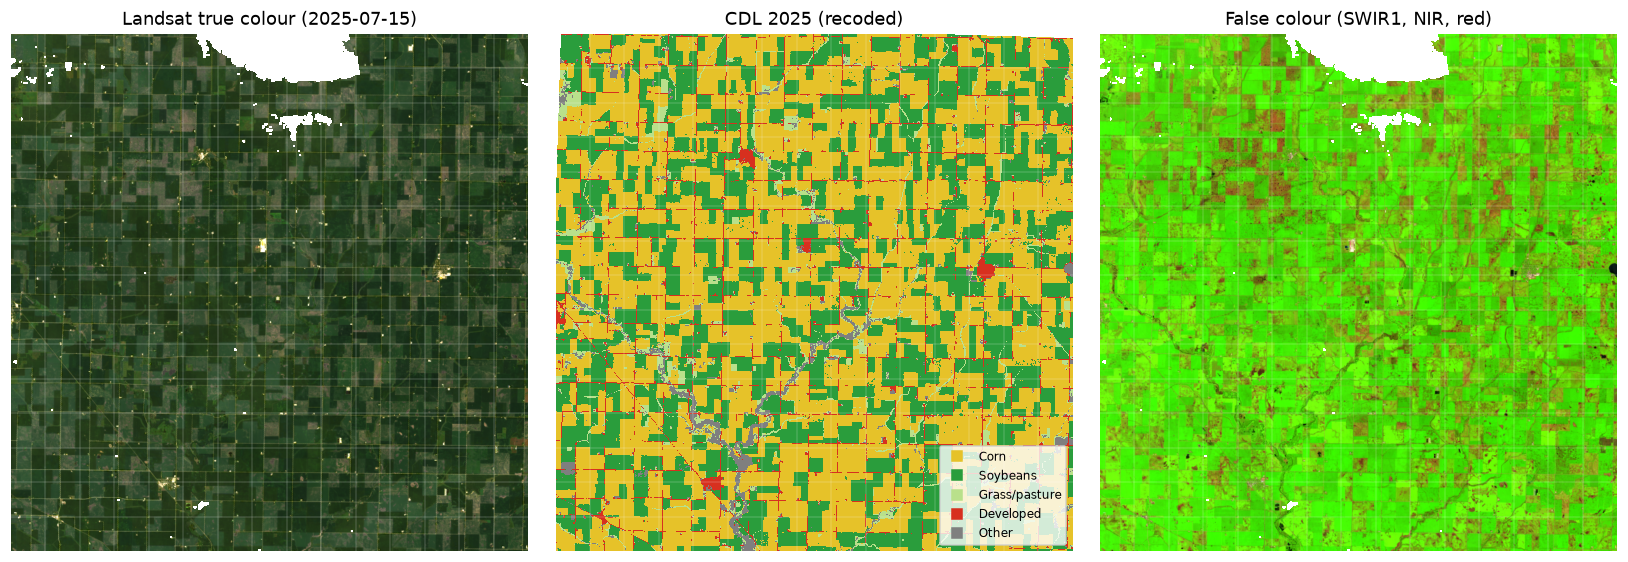

In [5]:
rgb = np.clip(arr[[2, 1, 0]].transpose(1, 2, 0) / 0.2, 0, 1)  # true colour, 0-20 % reflectance
cm = plt.matplotlib.colors.ListedColormap(["#e6c229", "#2a9d3c", "#b9e08b", "#d7301f", "#7f7f7f"])
fig, ax = plt.subplots(1, 3, figsize=(15, 5))  # three panels
ax[0].imshow(rgb); ax[0].set_title("Landsat true colour (2025-07-15)")  # true colour
ax[1].imshow(np.ma.masked_less(labg, 0), cmap=cm, vmin=0, vmax=4, interpolation="nearest")  # recoded CDL
ax[1].set_title("CDL 2025 (recoded)")  # title
for i, n in enumerate(NAMES):  # one legend entry ...
    ax[1].plot([], [], "s", c=cm(i), label=n)  # ... per class
ax[1].legend(loc="lower right", fontsize=8)  # the legend
sw = arr[[4, 3, 2]].transpose(1, 2, 0)  # SWIR 1, NIR, red
# stretched to 2-98 %
ax[2].imshow(np.clip((sw - np.nanpercentile(sw, 2)) / (np.nanpercentile(sw, 98) - np.nanpercentile(sw, 2)), 0, 1))
ax[2].set_title("False colour (SWIR1, NIR, red)")  # title
for a in ax:  # every panel ...
    a.axis("off")  # no axes
    # thin white lines at the block edges
    for k in range(1, nb): a.axhline(k * BLOCK - .5, c="w", lw=.15); a.axvline(k * BLOCK - .5, c="w", lw=.15)
plt.tight_layout(); plt.show()  # arrange and draw

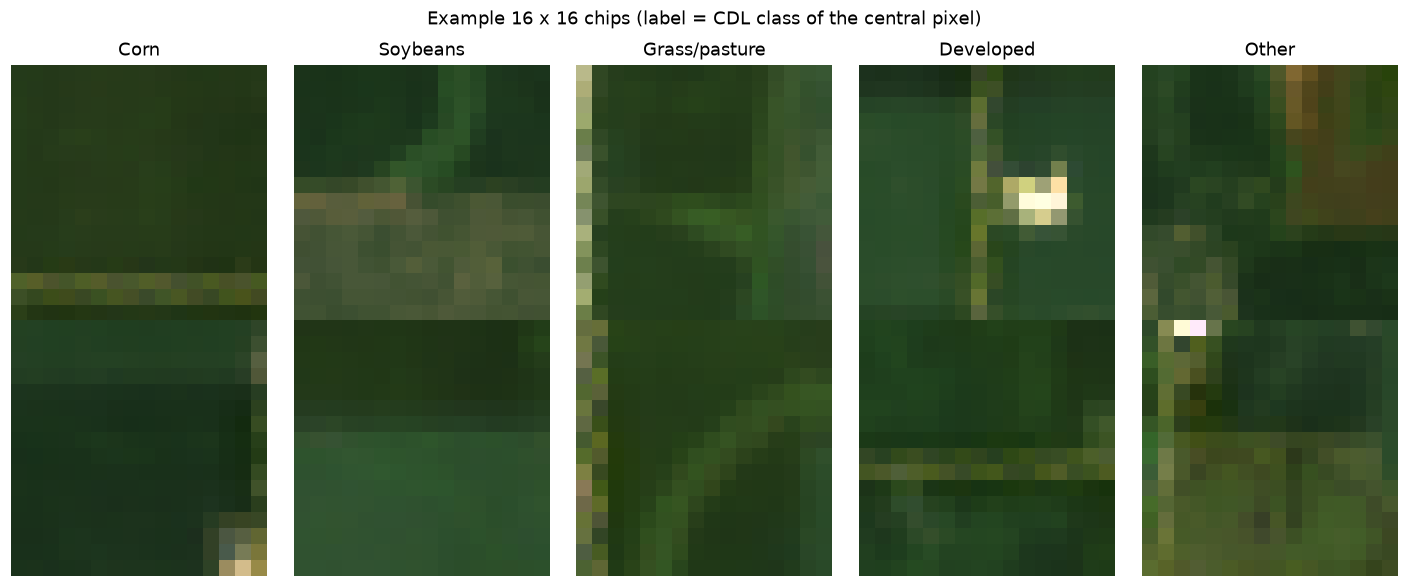

In [6]:
fig, ax = plt.subplots(2, 5, figsize=(13, 5.4))  # two example chips per class
rng = np.random.default_rng(1)  # random generator
for k in range(5):  # each class
    idx = rng.choice(np.flatnonzero(y == k), 2, replace=False)  # two random chips of it
    for r_, i in enumerate(idx):  # each chip
        c_ = np.clip(X[i][[2, 1, 0]].transpose(1, 2, 0) / 0.2, 0, 1)  # true colour
        ax[r_, k].imshow(c_, interpolation="nearest"); ax[r_, k].axis("off")  # draw it
        if r_ == 0: ax[r_, k].set_title(NAMES[k])  # class name above the first row
# title, arrange and draw
plt.suptitle("Example 16 x 16 chips (label = CDL class of the central pixel)"); plt.tight_layout(); plt.show()

### One configuration for both parts

The same network, optimiser and training settings are used in Part 1 and Part 2. Only the way the data are split, and whether the training chips are augmented, changes. `simple_cnn` is a compact network built into GeoLattice; it has three convolution blocks and a linear classifier.


In [7]:
# the training configuration
CFG = dict(arch="simple_cnn", in_channels=len(BANDS), num_classes=len(NAMES), dropout=0.3,
           epochs=40, batch_size=128, lr=2e-3, weight_decay=1e-4, scheduler="cosine",
           early_stopping=8, loss="ce", normalization="zscore (fitted on the training chips)")
for k, v in CFG.items():  # print every setting
    print(f"{k:14s}: {v}")  # one per line
# build the model once to inspect it
model0 = ic.build_cnn(CFG["arch"], in_channels=CFG["in_channels"], num_classes=CFG["num_classes"], dropout=CFG["dropout"])
print(model0)  # its layers
print("trainable parameters:", f"{ic.count_parameters(model0):,}")  # number of trainable weights

arch          : simple_cnn
in_channels   : 6
num_classes   : 5
dropout       : 0.3
epochs        : 40
batch_size    : 128
lr            : 0.002
weight_decay  : 0.0001
scheduler     : cosine
early_stopping: 8
loss          : ce
normalization : zscore (fitted on the training chips)
SimpleCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(6, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (1): Sequential(
      (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Sequential(
      (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=

In [8]:
def augment_chips(Xn, yn, copies, seed):  # add augmented copies of normalised chips
    '''Offline augmentation of *normalised* chips: dihedral transform + small radiometric jitter.'''
    # rotations, flips and small brightness, contrast and noise changes
    aug = ic.OverheadAugment(dihedral=True, brightness=0.05, contrast=0.05, noise=0.02, seed=seed)
    out_x, out_y = [Xn], [yn]  # start with the originals
    for _ in range(copies):  # each extra copy
        out_x.append(np.stack([aug(torch.from_numpy(x))[0].numpy() for x in Xn]))  # every chip transformed once
        out_y.append(yn)  # same labels
    return np.concatenate(out_x), np.concatenate(out_y)  # originals plus copies


# train the CNN of CFG on chips X[tr], validate on X[va]
def fit_cnn(tr, va, *, seed, augment_copies=0, verbose=False):
    '''Train the CNN of CFG on chips X[tr], validate on X[va]. The normaliser sees training chips only.'''
    norm = ic.Normalizer("zscore").fit(X[tr], band_axis=1)  # per-band z-score from the training chips only
    Xtr, ytr = ic.ChipDataset(X[tr], y[tr], normalizer=norm).images, y[tr]  # normalised training chips
    if augment_copies:  # augmentation requested
        Xtr, ytr = augment_chips(Xtr, ytr, augment_copies, seed)  # add the copies
    train_ds = ic.ChipDataset(Xtr, ytr)                       # already normalised
    val_ds = ic.ChipDataset(X[va], y[va], normalizer=norm)  # validation chips with the training normaliser
    ic.set_seed(seed)  # same initial weights for a given seed
    # build the CNN
    model = ic.build_cnn(CFG["arch"], in_channels=CFG["in_channels"], num_classes=CFG["num_classes"],
                         dropout=CFG["dropout"])
    w = ic.class_weights(ytr, num_classes=CFG["num_classes"])  # class weights against imbalance
    t0 = time.time()  # start the timer
    hist = ic.train_model(  # the GeoLattice training loop
        model, ic.as_loader(train_ds, CFG["batch_size"], seed=seed), ic.as_loader(val_ds, 512, shuffle=False),
        epochs=CFG["epochs"], loss=ic.get_loss(CFG["loss"], class_weights=w), lr=CFG["lr"],
        weight_decay=CFG["weight_decay"], scheduler=CFG["scheduler"], early_stopping=CFG["early_stopping"],
        num_classes=CFG["num_classes"], seed=seed, device=DEVICE, verbose=verbose)
    # model, scaler, history and run information
    return dict(model=model, norm=norm, hist=hist, seconds=time.time() - t0, n_train=len(ytr),
                tr=tr, va=va, epochs=len(hist["train_loss"]))


def predict(res, idx):  # class predictions for chips X[idx]
    ds = ic.ChipDataset(X[idx], normalizer=res["norm"])  # chips with the model's normaliser
    # most probable class
    return ic.predict_proba_batches(res["model"], ds, batch_size=512, device=DEVICE).argmax(1)


def report(res, idx, n_boot=0):  # accuracy report for chips X[idx]
    # against the chip labels
    return ic.classification_report(y[idx], predict(res, idx), labels=range(len(NAMES)),
                                    class_names=dict(enumerate(NAMES)), n_boot=n_boot, seed=0)

## Part 1: one global split into train / validation / test

All 225 blocks are shuffled once and divided 60 / 20 / 20 into train / validation / test (`group_split` on the block ID). The validation blocks steer early stopping and checkpoint choice; the test blocks are touched once, at the end.


train 6,286 | val 2,135 | test 2,090 chips  | blocks: 133/45/45


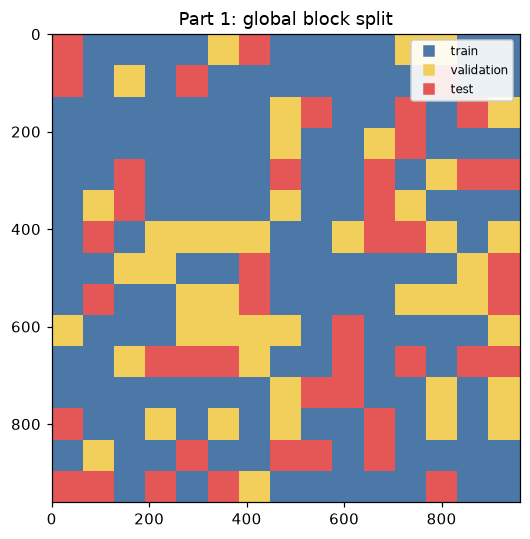

In [9]:
def global_split(seed):  # split whole blocks: 60 / 20 / 20
    # blocks to train, validation and test
    s = ic.group_split(meta.block.values, test_size=0.2, val_size=0.2, seed=seed)
    # no block in two splits
    ic.check_split_isolation(train=meta.block.values[s.train], val=meta.block.values[s.val], test=meta.block.values[s.test])
    return s.train, s.val, s.test  # chip indices of each split

tr1, va1, te1 = global_split(0)  # the split used in Part 1
print(f"train {len(tr1):,} | val {len(va1):,} | test {len(te1):,} chips  "  # chips and blocks per split
      f"| blocks: {meta.block.values[tr1].size and len(np.unique(meta.block.values[tr1]))}/"
      f"{len(np.unique(meta.block.values[va1]))}/{len(np.unique(meta.block.values[te1]))}")

role = np.full((nb, nb), 0)  # role of every block on the grid
for code_, ids in ((0, tr1), (1, va1), (2, te1)):  # each split ...
    for b in np.unique(meta.block.values[ids]): role[b // nb, b % nb] = code_  # ... marks its blocks
fig, ax = plt.subplots(figsize=(5, 5))  # one panel
ax.imshow(role, cmap=plt.matplotlib.colors.ListedColormap(["#4c78a8", "#f2cf5b", "#e45756"]), extent=(0, N, N, 0))
for i, (n, c) in enumerate(zip(["train", "validation", "test"], ["#4c78a8", "#f2cf5b", "#e45756"])): ax.plot([], [], "s", c=c, label=n)
# legend and title
ax.legend(loc="upper right", fontsize=8, framealpha=.9); ax.set_title("Part 1: global block split")
plt.tight_layout(); plt.show()  # arrange and draw

In [10]:
res1 = fit_cnn(tr1, va1, seed=0, augment_copies=0, verbose=True)  # train the Part 1 model
# training size, epochs and time
print(f"\ntrained on {res1['n_train']:,} chips for {res1['epochs']} epochs in {res1['seconds']:.0f} s on {DEVICE}")

epoch 1/40 train_loss=0.5897 val_loss=0.4767 val_score=0.8426
epoch 2/40 train_loss=0.4200 val_loss=0.4095 val_score=0.8693


epoch 3/40 train_loss=0.3774 val_loss=0.4095 val_score=0.8623
epoch 4/40 train_loss=0.3492 val_loss=0.3919 val_score=0.8679


epoch 5/40 train_loss=0.3294 val_loss=0.3430 val_score=0.8843
epoch 6/40 train_loss=0.3160 val_loss=0.3447 val_score=0.8862


epoch 7/40 train_loss=0.3027 val_loss=0.3509 val_score=0.8759
epoch 8/40 train_loss=0.2902 val_loss=0.3814 val_score=0.8838


epoch 9/40 train_loss=0.2780 val_loss=0.3192 val_score=0.8909
epoch 10/40 train_loss=0.2630 val_loss=0.3279 val_score=0.8829


epoch 11/40 train_loss=0.2573 val_loss=0.4310 val_score=0.8468
epoch 12/40 train_loss=0.2519 val_loss=0.3166 val_score=0.8965


... (7 outputs left out)

epoch 27/40 train_loss=0.1604 val_loss=0.2892 val_score=0.9073
epoch 28/40 train_loss=0.1541 val_loss=0.2971 val_score=0.9073


epoch 29/40 train_loss=0.1520 val_loss=0.2913 val_score=0.9044
epoch 30/40 train_loss=0.1423 val_loss=0.2911 val_score=0.9087


epoch 31/40 train_loss=0.1444 val_loss=0.3002 val_score=0.9073
epoch 32/40 train_loss=0.1371 val_loss=0.2864 val_score=0.9063


epoch 33/40 train_loss=0.1344 val_loss=0.2967 val_score=0.9068
epoch 34/40 train_loss=0.1358 val_loss=0.2883 val_score=0.9091
early stopping at epoch 34

trained on 6,286 chips for 34 epochs in 7 s on cuda


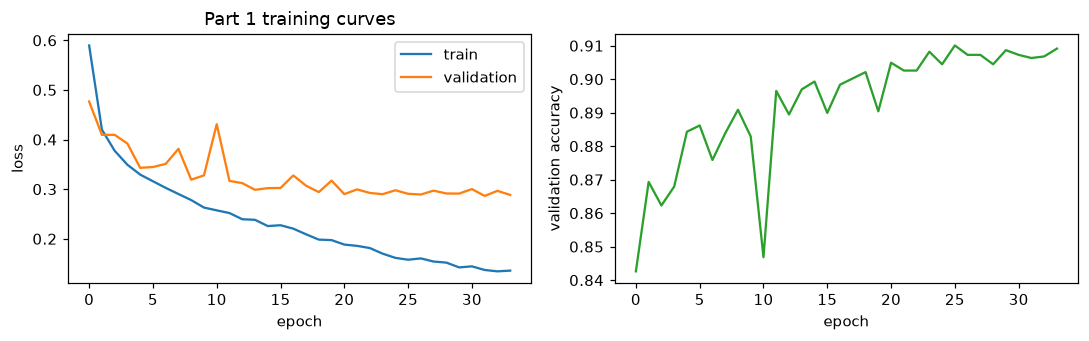

In [11]:
def plot_history(h, title):  # loss and accuracy curves
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))  # two panels
    # training and validation loss
    ax[0].plot(h["train_loss"], label="train"); ax[0].plot(h["val_loss"], label="validation")
    # labels and legend
    ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss"); ax[0].legend(); ax[0].set_title(title)
    # validation accuracy
    ax[1].plot(h["val_score"], c="C2"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("validation accuracy")
    plt.tight_layout(); plt.show()  # arrange and draw

plot_history(res1["hist"], "Part 1 training curves")  # the Part 1 curves

In [12]:
rep1 = report(res1, te1, n_boot=500)  # test report with 500 bootstrap repeats
ci = rep1["ci"]  # confidence intervals
# scores with their 95 % intervals
print(f"TEST (n={rep1['n']:,}): OA {rep1['overall_accuracy']:.3f} [{ci['oa'][0]:.3f}, {ci['oa'][1]:.3f}] | "
      f"kappa {rep1['kappa']:.3f} [{ci['kappa'][0]:.3f}, {ci['kappa'][1]:.3f}] | "
      f"macro-F1 {rep1['macro_f1']:.3f} [{ci['macro_f1'][0]:.3f}, {ci['macro_f1'][1]:.3f}]")
rep1["per_class"].round(3)  # per-class scores

TEST (n=2,090): OA 0.907 [0.894, 0.918] | kappa 0.839 [0.818, 0.858] | macro-F1 0.718 [0.670, 0.759]


,precision,recall,f1,support,f1_ci_low,f1_ci_high
Corn,0.948,0.965,0.956,1125,0.947,0.965
Soybeans,0.903,0.952,0.927,713,0.914,0.941
Grass/pasture,0.552,0.542,0.547,59,0.425,0.638
Developed,0.714,0.556,0.625,144,0.556,0.691
Other,0.864,0.388,0.535,49,0.372,0.667


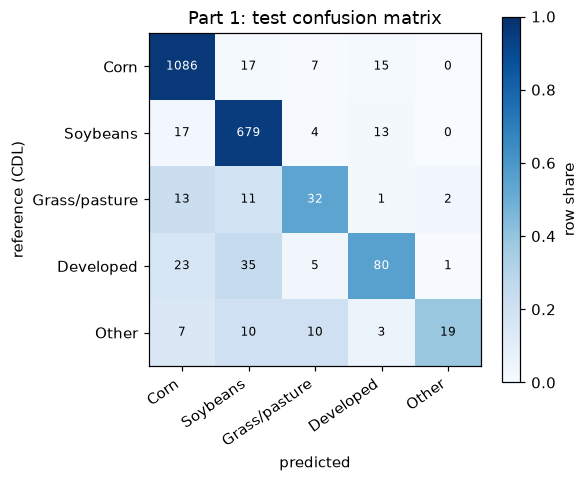

In [13]:
def plot_cm(rep, title):  # draw a row-normalised confusion matrix
    # counts and row shares
    cmx = rep["confusion_matrix"]; frac = cmx.values / cmx.values.sum(1, keepdims=True).clip(1)
    fig, ax = plt.subplots(figsize=(5.4, 4.6)); im = ax.imshow(frac, cmap="Blues", vmin=0, vmax=1)  # one panel
    # class names on both axes
    ax.set_xticks(range(5)); ax.set_xticklabels(cmx.columns, rotation=35, ha="right"); ax.set_yticks(range(5)); ax.set_yticklabels(cmx.index)
    for i in range(5):  # every cell ...
        for j in range(5):  # ...
            # its count
            ax.text(j, i, int(cmx.values[i, j]), ha="center", va="center", color="white" if frac[i, j] > .5 else "black", fontsize=8)
    # labels, title and colour bar
    ax.set_xlabel("predicted"); ax.set_ylabel("reference (CDL)"); ax.set_title(title); plt.colorbar(im, label="row share")
    plt.tight_layout(); plt.show()  # arrange and draw

plot_cm(rep1, "Part 1: test confusion matrix")  # the Part 1 matrix

### A map from the CNN

`predict_chip_map` slides the trained chip classifier over the scene (here with stride 8 pixels) and assigns every pixel the class of its nearest chip centre. The map is judged only on the **test blocks**: elsewhere the network was trained on those pixels.


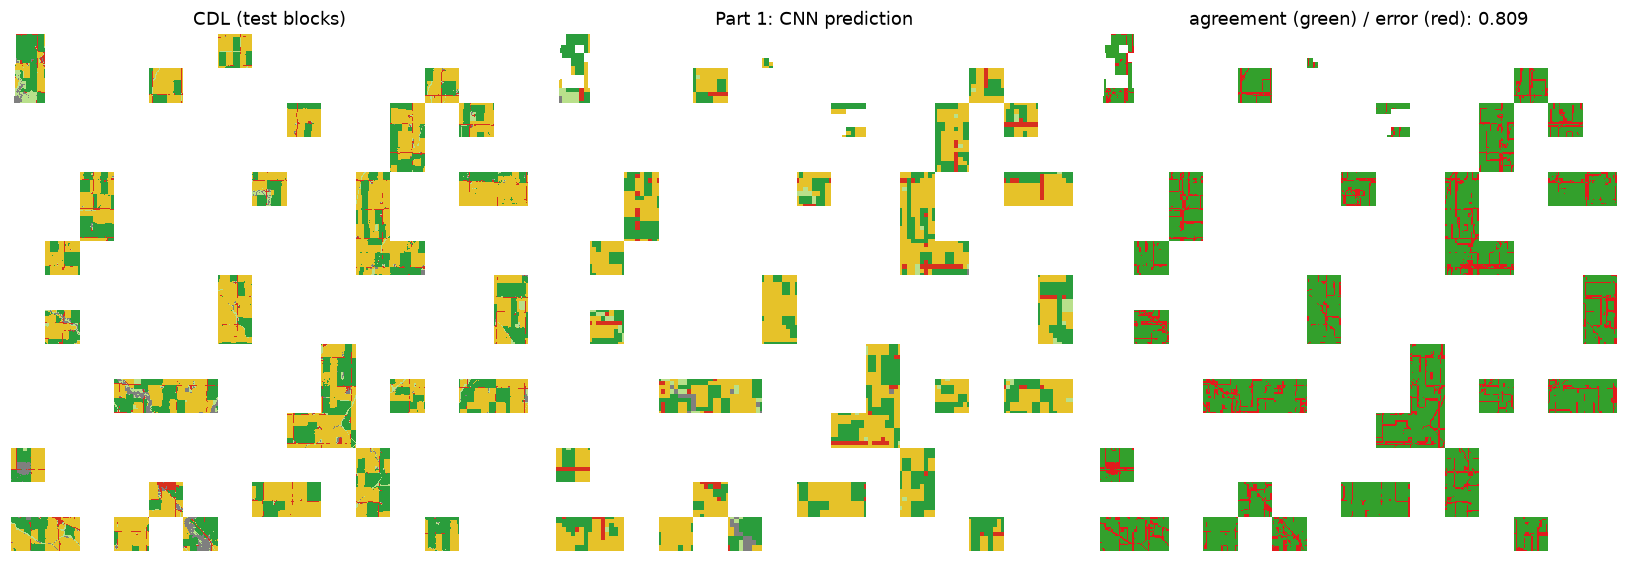

In [14]:
def chip_map(res, stride=8):  # class map from a sliding chip window
    da = refl.isel(x=slice(0, N), y=slice(0, N)).copy()  # the cropped scene
    # predicted class of each chip, painted on its pixels
    return ic.predict_chip_map(res["model"], da, size=SIZE, stride=stride, normalizer=res["norm"], device=DEVICE).values


def test_mask(ids):  # boolean mask of the test blocks
    m = np.zeros((N, N), bool)  # empty mask
    for b in np.unique(meta.block.values[ids]):  # each test block
        i, j = divmod(b, nb); m[i * BLOCK:(i + 1) * BLOCK, j * BLOCK:(j + 1) * BLOCK] = True  # its pixel window
    return m  # the mask


def show_map(res, ids, title):  # reference, prediction and agreement in the test blocks
    pm = chip_map(res); tm = test_mask(ids)  # predicted map and test mask
    valid = (pm >= 0) & (labg >= 0)  # pixels with a prediction and a label
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))  # three panels
    # reference in the test blocks
    ax[0].imshow(np.ma.masked_where(~tm | (labg < 0), labg), cmap=cm, vmin=0, vmax=4, interpolation="nearest"); ax[0].set_title("CDL (test blocks)")
    # prediction in the test blocks
    ax[1].imshow(np.ma.masked_where(~tm | ~valid, pm), cmap=cm, vmin=0, vmax=4, interpolation="nearest"); ax[1].set_title(f"{title}: CNN prediction")
    err = np.where(tm & valid, (pm == labg).astype(float), np.nan)  # 1 = correct, 0 = wrong
    ax[2].imshow(np.ma.masked_invalid(err), cmap=plt.matplotlib.colors.ListedColormap(["#e31a1c", "#33a02c"]), vmin=0, vmax=1, interpolation="nearest")
    ax[2].set_title(f"agreement (green) / error (red): {np.nanmean(err):.3f}")  # title with the agreement
    for a in ax: a.axis("off")  # no axes
    plt.tight_layout(); plt.show()  # arrange and draw

show_map(res1, te1, "Part 1")  # maps of Part 1

## Part 2: tiles, per-tile splits and augmentation, then merge

Part 1 splits the scene as a whole, so a tile that happens to hold unusual fields can end up almost entirely in the test set. Part 2 forces **every tile to contribute to every split**:

1. Cut the Landsat scene **and** the CDL into $3\times3=9$ tiles of $320\times320$ pixels (each $5\times5$ blocks), using the same block grid.
2. In each tile, split its blocks 60 / 20 / 20 into train / validation / test.
3. Augment the **training** chips of each tile (original + 3 augmented copies; 8 dihedral rotations / flips with a little brightness, contrast and noise jitter). Validation and test chips are never augmented.
4. Merge the 9 train, 9 validation and 9 test parts into one train, one validation and one test set, and train the same CNN.


In [15]:
def tile_split(seed):  # split blocks separately inside each 5 x 5-block tile
    tr, va, te = [], [], []  # indices per split
    for t in sorted(meta.tile.unique()):  # each tile
        idx = np.flatnonzero(meta.tile.values == t)  # its chips
        # 60 / 20 / 20 block split inside the tile
        s = ic.group_split(meta.block.values[idx], test_size=0.2, val_size=0.2, seed=seed + 100 * int(t))
        tr.append(idx[s.train]); va.append(idx[s.val]); te.append(idx[s.test])  # collect the indices
    tr, va, te = (np.concatenate(a) for a in (tr, va, te))  # merge the tiles
    # no block in two splits
    ic.check_split_isolation(train=meta.block.values[tr], val=meta.block.values[va], test=meta.block.values[te])
    return tr, va, te  # the merged split

tr2, va2, te2 = tile_split(0)  # the split used in Part 2
print(f"merged: train {len(tr2):,} | val {len(va2):,} | test {len(te2):,} chips")  # split sizes
# chips per tile and split, then name the index
tab = pd.DataFrame({s: pd.Series(meta.tile.values[ids]).value_counts().sort_index()
                    for s, ids in (("train", tr2), ("val", va2), ("test", te2))}); tab.index.name = "tile"
tab.T  # one column per tile

merged: train 6,231 | val 2,127 | test 2,153 chips


tile,0,1,2,3,4,5,6,7,8
train,686,440,724,729,735,735,729,718,735
val,230,193,245,244,241,245,239,245,245
test,239,203,245,245,245,245,245,241,245


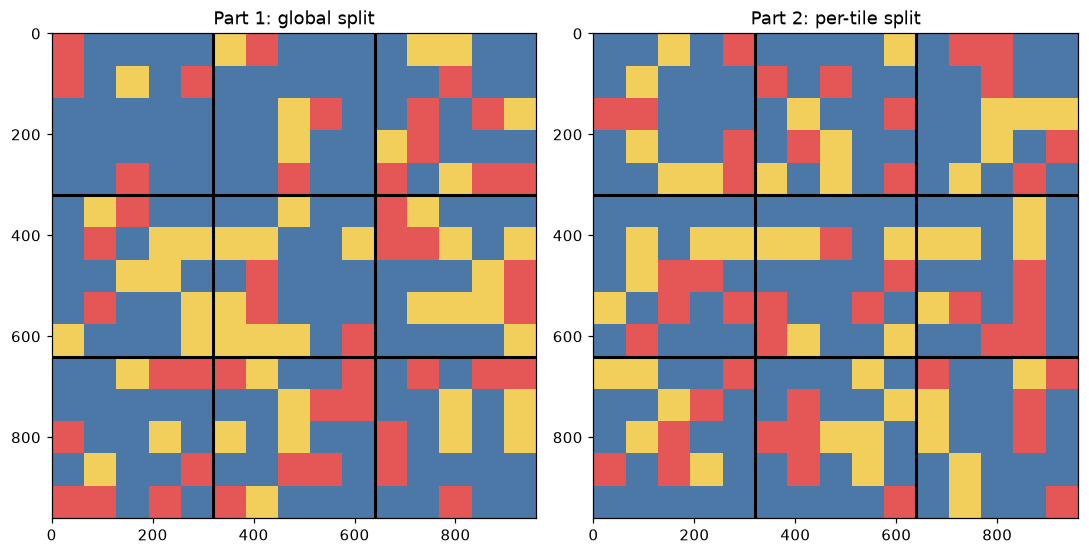

In [16]:
role2 = np.full((nb, nb), 0)  # role of every block in Part 2
for code_, ids in ((0, tr2), (1, va2), (2, te2)):  # each split ...
    for b in np.unique(meta.block.values[ids]): role2[b // nb, b % nb] = code_  # ... marks its blocks
fig, ax = plt.subplots(1, 2, figsize=(10, 5))  # two panels
# Part 1 and Part 2 side by side
for a, rl, t in zip(ax, (role, role2), ("Part 1: global split", "Part 2: per-tile split")):
    a.imshow(rl, cmap=plt.matplotlib.colors.ListedColormap(["#4c78a8", "#f2cf5b", "#e45756"]), extent=(0, N, N, 0)); a.set_title(t)
    for k in range(1, 3):  # tile boundaries ...
        # ... in black
        a.axhline(k * TILE_BLOCKS * BLOCK, c="k", lw=2); a.axvline(k * TILE_BLOCKS * BLOCK, c="k", lw=2)
plt.tight_layout(); plt.show()  # arrange and draw

Black lines are tile borders. Every tile now holds train, validation and test blocks. Next, what augmentation does to a chip (shown in normalised units):


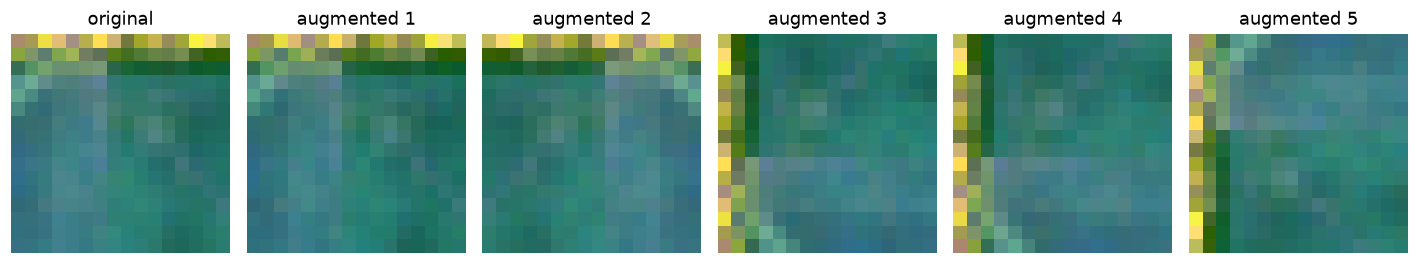

In [17]:
norm_demo = ic.Normalizer("zscore").fit(X[tr2], band_axis=1)  # a normaliser from the Part 2 training chips
Xn = ic.ChipDataset(X[tr2[:1]], normalizer=norm_demo).images  # one normalised chip
# the augmentation used in Part 2
aug = ic.OverheadAugment(dihedral=True, brightness=0.05, contrast=0.05, noise=0.02, seed=3)
fig, ax = plt.subplots(1, 6, figsize=(13, 2.4))  # six panels
# draw a chip as stretched true colour
show = lambda a, c: a.imshow(np.clip((c[[2, 1, 0]].transpose(1, 2, 0) - c[[2, 1, 0]].min()) / np.ptp(c[[2, 1, 0]]), 0, 1), interpolation="nearest")
show(ax[0], Xn[0]); ax[0].set_title("original")  # the original
for k in range(1, 6):  # five augmented versions ...
    # ... of the same chip
    show(ax[k], aug(torch.from_numpy(Xn[0]))[0].numpy()); ax[k].set_title(f"augmented {k}")
for a in ax: a.axis("off")  # no axes
plt.tight_layout(); plt.show()  # arrange and draw

epoch 1/40 train_loss=0.4918 val_loss=0.3900 val_score=0.8773


epoch 2/40 train_loss=0.3902 val_loss=0.3491 val_score=0.8801


epoch 3/40 train_loss=0.3622 val_loss=0.3036 val_score=0.8919


epoch 4/40 train_loss=0.3482 val_loss=0.3212 val_score=0.8890


epoch 5/40 train_loss=0.3283 val_loss=0.2851 val_score=0.8923


epoch 6/40 train_loss=0.3212 val_loss=0.2952 val_score=0.8952


... (13 outputs left out)

epoch 20/40 train_loss=0.2203 val_loss=0.2974 val_score=0.8947


epoch 21/40 train_loss=0.2159 val_loss=0.2833 val_score=0.8994


epoch 22/40 train_loss=0.2119 val_loss=0.2924 val_score=0.8970


epoch 23/40 train_loss=0.2071 val_loss=0.2994 val_score=0.8999
early stopping at epoch 23

trained on 24,924 chips (6,231 real + augmented) for 23 epochs in 14 s on cuda


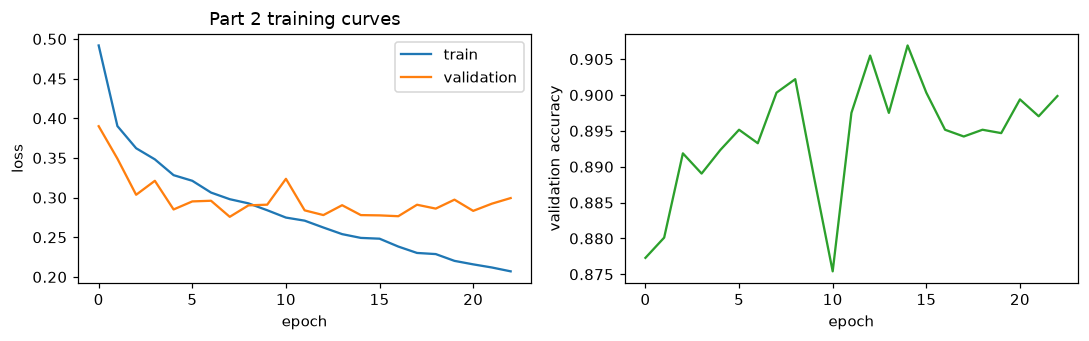

In [18]:
# train the Part 2 model with 3 augmented copies
res2 = fit_cnn(tr2, va2, seed=0, augment_copies=3, verbose=True)
# training size, epochs and time
print(f"\ntrained on {res2['n_train']:,} chips ({len(tr2):,} real + augmented) for {res2['epochs']} epochs in {res2['seconds']:.0f} s on {DEVICE}")
plot_history(res2["hist"], "Part 2 training curves")  # its curves

In [19]:
rep2 = report(res2, te2, n_boot=500)  # test report with 500 bootstrap repeats
ci = rep2["ci"]  # confidence intervals
# scores with their 95 % intervals
print(f"TEST (n={rep2['n']:,}): OA {rep2['overall_accuracy']:.3f} [{ci['oa'][0]:.3f}, {ci['oa'][1]:.3f}] | "
      f"kappa {rep2['kappa']:.3f} [{ci['kappa'][0]:.3f}, {ci['kappa'][1]:.3f}] | "
      f"macro-F1 {rep2['macro_f1']:.3f} [{ci['macro_f1'][0]:.3f}, {ci['macro_f1'][1]:.3f}]")
rep2["per_class"].round(3)  # per-class scores

TEST (n=2,153): OA 0.901 [0.888, 0.914] | kappa 0.825 [0.804, 0.847] | macro-F1 0.664 [0.619, 0.707]


,precision,recall,f1,support,f1_ci_low,f1_ci_high
Corn,0.934,0.960,0.947,1185,0.938,0.957
Soybeans,0.955,0.931,0.943,749,0.930,0.955
Grass/pasture,0.607,0.459,0.523,74,0.419,0.628
Developed,0.456,0.576,0.509,99,0.409,0.585
Other,0.583,0.304,0.400,46,0.262,0.542


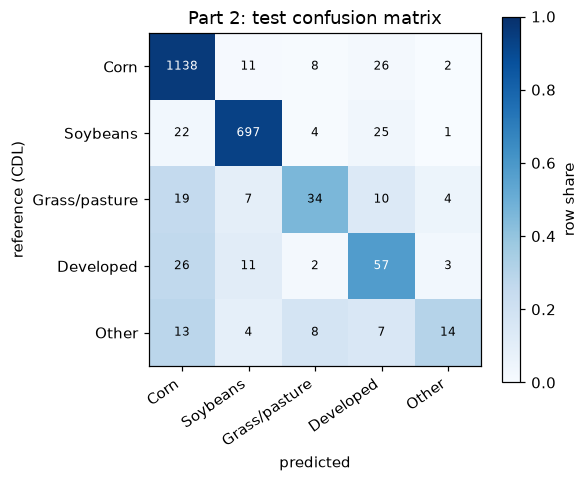

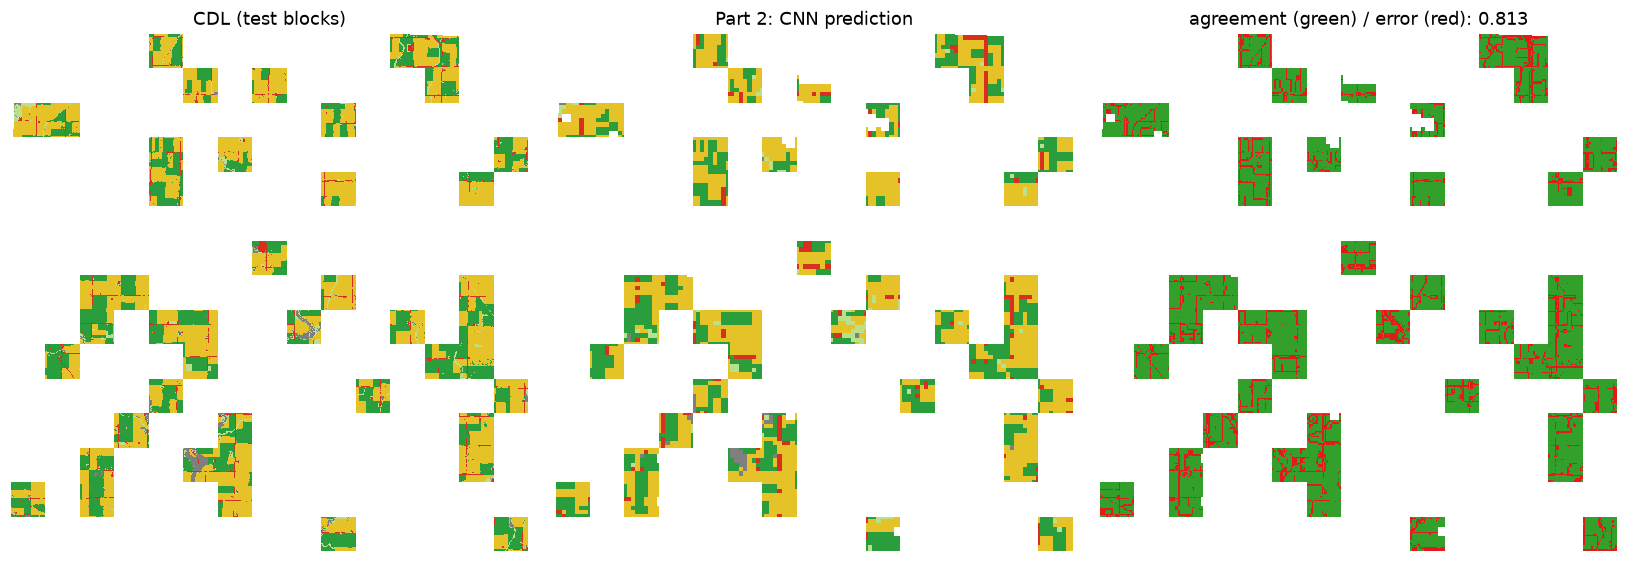

In [20]:
plot_cm(rep2, "Part 2: test confusion matrix")  # the Part 2 matrix
show_map(res2, te2, "Part 2")  # and maps

## Part 3: which approach is better?

Two points make the comparison tricky:

1. **The two parts have different test sets.** A higher score on an easier set of blocks proves nothing. The fair measures are the **common test set** (chips that are test chips in *both* splits, so neither model has seen them or their neighbours) and **repetition over seeds**.
2. **Two things changed at once** (split scheme and augmentation). A 2 × 2 ablation separates them: `global` or `tile` split, each with or without augmentation.

We train all four configurations for three seeds. A seed changes the block assignment, the network initialisation and the batch order.


In [21]:
SEEDS = [0, 1, 2]  # three seeds per configuration
CONFIGS = {"A: global split":        ("global", 0),  # split scheme and number of augmented copies
           "B: tile split + augment": ("tile", 3),      # = Part 2
           "C: global + augment":    ("global", 3),
           "D: tile split":          ("tile", 0)}       # tile split without augmentation
# the two seed-0 models already trained
cache = {("A: global split", 0): (res1, (tr1, va1, te1)), ("B: tile split + augment", 0): (res2, (tr2, va2, te2))}
# global splits for every seed
splits = {("global", s): (global_split(s) if s else (tr1, va1, te1)) for s in SEEDS}
splits |= {("tile", s): (tile_split(s) if s else (tr2, va2, te2)) for s in SEEDS}  # tile splits for every seed

for name, (kind, copies) in CONFIGS.items():  # every configuration ...
    for s in SEEDS:  # ... and seed
        if (name, s) in cache: continue  # skip models already trained
        sp = splits[(kind, s)]  # its split
        # train and keep the model
        cache[(name, s)] = (fit_cnn(sp[0], sp[1], seed=s, augment_copies=copies), sp)
print("trained", len(cache), "models")  # total trained

trained 12 models


In [22]:
rows = []  # one row per model
for (name, s), (res, (tr, va, te)) in cache.items():  # every trained model
    kind = CONFIGS[name][0]  # its split scheme
    other = splits[("tile" if kind == "global" else "global", s)][2]  # test chips of the other scheme
    common = np.intersect1d(te, other)                      # test chips in both split schemes
    r_own, r_com = report(res, te), report(res, common)  # scores on its own and on the common test set
    # one result row
    rows.append({"config": name, "seed": s, "own_OA": r_own["overall_accuracy"], "own_kappa": r_own["kappa"],
                 "own_macroF1": r_own["macro_f1"], "common_n": len(common), "common_OA": r_com["overall_accuracy"],
                 "common_macroF1": r_com["macro_f1"], "n_train": res["n_train"], "epochs": res["epochs"]})
R = pd.DataFrame(rows)  # as a table
R.round(3).sort_values(["config", "seed"])  # sorted

,config,seed,own_OA,own_kappa,own_macroF1,common_n,common_OA,common_macroF1,n_train,epochs
0,A: global split,0,0.907,0.839,0.718,196,0.939,0.793,6286,34
2,A: global split,1,0.899,0.826,0.678,459,0.937,0.712,6331,29
3,A: global split,2,0.909,0.844,0.692,441,0.905,0.728,6281,40
1,B: tile split + augment,0,0.901,0.825,0.664,196,0.903,0.784,24924,23
4,B: tile split + augment,1,0.897,0.810,0.566,459,0.926,0.606,25272,12
5,B: tile split + augment,2,0.899,0.819,0.633,441,0.887,0.674,24992,18
6,C: global + augment,0,0.888,0.804,0.691,196,0.923,0.700,25144,40
7,C: global + augment,1,0.890,0.811,0.655,459,0.946,0.746,25324,17
8,C: global + augment,2,0.904,0.835,0.636,441,0.900,0.679,25124,19
9,D: tile split,0,0.907,0.831,0.608,196,0.944,0.761,6231,17


In [23]:
# mean and spread over the seeds
S = R.groupby("config").agg(own_OA=("own_OA", "mean"), own_OA_sd=("own_OA", "std"), own_kappa=("own_kappa", "mean"),
                            own_macroF1=("own_macroF1", "mean"), common_OA=("common_OA", "mean"),
                            common_OA_sd=("common_OA", "std"), common_macroF1=("common_macroF1", "mean"),
                            n_train=("n_train", "mean"))
S = S.loc[list(CONFIGS)]  # in configuration order
S.round(3)  # show it

,own_OA,own_OA_sd,own_kappa,own_macroF1,common_OA,common_OA_sd,common_macroF1,n_train
config,,,,,,,,
A: global split,0.905,0.006,0.837,0.696,0.927,0.019,0.744,6299.333
B: tile split + augment,0.899,0.002,0.818,0.621,0.905,0.020,0.688,25062.667
C: global + augment,0.894,0.009,0.817,0.661,0.923,0.023,0.709,25197.333
D: tile split,0.907,0.004,0.832,0.640,0.925,0.031,0.721,6265.667


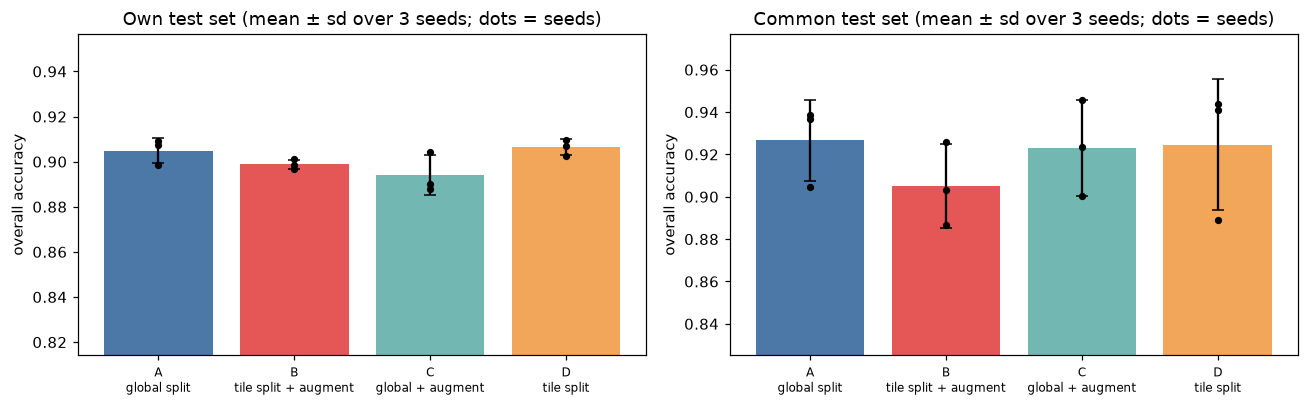

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))  # two panels
# own and common test set
for a, (m, sd, t) in zip(ax, (("own_OA", "own_OA_sd", "Own test set"), ("common_OA", "common_OA_sd", "Common test set"))):
    a.bar(range(4), S[m], yerr=S[sd], capsize=4, color=["#4c78a8", "#e45756", "#72b7b2", "#f2a65a"])
    for s in SEEDS:  # each seed ...
        # ... as a dot
        a.scatter(range(4), R[R.seed == s].set_index("config").loc[S.index, m], c="k", s=14, zorder=3)
    # configuration labels
    a.set_xticks(range(4)); a.set_xticklabels([c.split(": ")[0] + "\n" + c.split(": ")[1] for c in S.index], fontsize=8)
    # limits, title and label
    a.set_ylim(max(0, S[m].min() - .08), min(1, S[m].max() + .05)); a.set_title(t + " (mean ± sd over 3 seeds; dots = seeds)"); a.set_ylabel("overall accuracy")
plt.tight_layout(); plt.show()  # arrange and draw

In [25]:
effect = pd.DataFrame({  # effect of each choice on accuracy
    "augmentation (global split)": R[R.config == "C: global + augment"].set_index("seed")[["own_OA", "common_OA"]].mean()
                                  - R[R.config == "A: global split"].set_index("seed")[["own_OA", "common_OA"]].mean(),
    "augmentation (tile split)":   R[R.config == "B: tile split + augment"].set_index("seed")[["own_OA", "common_OA"]].mean()
                                  - R[R.config == "D: tile split"].set_index("seed")[["own_OA", "common_OA"]].mean(),
    "tile vs global split (no aug)": R[R.config == "D: tile split"].set_index("seed")[["own_OA", "common_OA"]].mean()
                                  - R[R.config == "A: global split"].set_index("seed")[["own_OA", "common_OA"]].mean(),
})
print("Mean change in overall accuracy (percentage points):")  # header
(100 * effect).round(2)  # in percentage points

Mean change in overall accuracy (percentage points):


,augmentation (global split),augmentation (tile split),tile vs global split (no aug)
own_OA,-1.07,-0.77,0.16
common_OA,-0.37,-1.94,-0.21


In [26]:
best = S["common_OA"].idxmax(); best_own = S["own_OA"].idxmax()  # best configuration on each test set
# the best on the common test set
print(f"Best on the common test set: {best} (OA {S.loc[best, 'common_OA']:.3f} ± {S.loc[best, 'common_OA_sd']:.3f})")
# the best on its own test set
print(f"Best on its own test set   : {best_own} (OA {S.loc[best_own, 'own_OA']:.3f} ± {S.loc[best_own, 'own_OA_sd']:.3f})")
print()  # blank line
# Part 1 against Part 2
print(f"Part 1 vs Part 2 (seed 0, own tests): OA {rep1['overall_accuracy']:.3f} vs {rep2['overall_accuracy']:.3f}; "
      f"kappa {rep1['kappa']:.3f} vs {rep2['kappa']:.3f}; macro-F1 {rep1['macro_f1']:.3f} vs {rep2['macro_f1']:.3f}")
# per-class F1 of both
pc = pd.DataFrame({"Part 1 (A)": rep1["per_class"]["f1"], "Part 2 (B)": rep2["per_class"]["f1"]})
pc.round(3)  # show it

Best on the common test set: A: global split (OA 0.927 ± 0.019)
Best on its own test set   : D: tile split (OA 0.907 ± 0.004)

Part 1 vs Part 2 (seed 0, own tests): OA 0.907 vs 0.901; kappa 0.839 vs 0.825; macro-F1 0.718 vs 0.664


,Part 1 (A),Part 2 (B)
Corn,0.956,0.947
Soybeans,0.927,0.943
Grass/pasture,0.547,0.523
Developed,0.625,0.509
Other,0.535,0.400


### Reading the results

* **Part 1 vs Part 2.** On their own test sets the single global split scored OA 0.910 / kappa 0.846 / macro-F1 0.727 and the tile + augmentation approach 0.902 / 0.825 / 0.633 (seed 0). Over three seeds the OA gap is about 0.9 points (0.909 vs 0.900), with a clearly larger gap in macro-F1 (0.70 vs 0.64), so **the plain global split (A) and the tile split without augmentation (D) performed best here**; the two are indistinguishable (0.909 vs 0.911).
* **The ablation says why.** Switching to a tile split changes OA by about 0.1 points: it makes the *evaluation* more representative (every tile appears in train, validation and test), but it does not make the model more accurate. **Augmentation lowered OA by about 1.1 points** in both split schemes and lowered macro-F1 on the tile split, mainly through the rare classes. Dihedral copies plus brightness, contrast and noise jitter can blur the fine spectral differences that separate those classes from crops.
* **The spread across seeds is the yardstick.** Differences of a few tenths of a point are within noise; the augmentation effect on OA is only about one standard deviation of the seeds, and the ranking of the rare classes is noisy because they have only 50 to 150 test chips per split.
* **Practical advice.** Start with the plain block split. Use a tile-wise split when you want every part of the landscape represented in the test data. Add augmentation only if it improves the *validation* score; try milder settings (flips and rotations without radiometric jitter), more epochs and a weaker class weighting before concluding it cannot help.
* **Scope.** All results are for one date, one region and one year of labels, with spatially disjoint blocks inside the same scene. A model that must work in another county or year needs a geographically separate test set (see `geographic_holdout` in `image_classification`).


## Testing both approaches on six tiles outside the training AOI

One outside area is a single draw: its score depends on the fields it happens to contain. To support a conclusion, the trained models are applied, **without any retraining**, to **six separate tiles** that lie outside the training AOI. Each tile has the size of the AOI and none overlaps the AOI or another tile:

| Tile | Position relative to the AOI |
|---|---|
| N, NE, E | north, north-east, east |
| W | west |
| S, SE | south, south-east |

* All tiles come from the **same Landsat scene** (2025-07-15) and **CDL 2025**, so sensor, season and class definitions are identical; only the geography changes. They were fetched with the project scripts, e.g. `download_landsat.py --aoi outside_aoi/tiles/N/aoi.geojson --years 2025 2025 --months 7` and `download_cdl.py --aoi outside_aoi/tiles/N/aoi.geojson --years 2025 2025`.
* Each model keeps the normaliser fitted on **its own training chips**.
* Uncertainty is reported as the **standard deviation (SD) across the six tiles**; for the 12-model comparison the tile scores are first averaged over the three training seeds, and the SD over seeds is shown separately.
* With six tiles, differences smaller than about one SD should not be called real; paired tests across tiles are used for the two main approaches.


overlap with the training AOI: {'N': 0.0, 'NE': 0.0, 'E': 0.0, 'W': 0.0, 'S': 0.0, 'SE': 0.0}
overlap between tiles        : 0.0


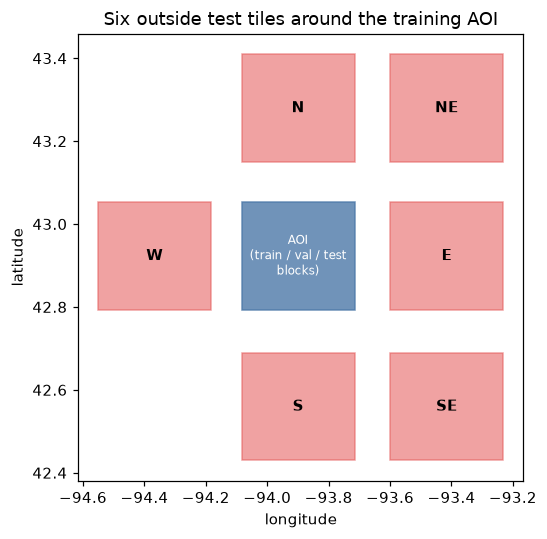

In [27]:
from shapely.geometry import shape  # polygon geometry from GeoJSON
from scipy import stats  # statistical tests

OUT_DIR = DATA / "outside_aoi"  # the outside-AOI tiles
SCENE_NAME = "2025_07_LC08_L2SP_027030_20250715_02_T1"  # the same Landsat date
# tile name -> folder
TILE_DIRS = {"E": OUT_DIR, **{t: OUT_DIR / "tiles" / t for t in ("N", "NE", "W", "S", "SE")}}
TILE_GRID = [["N", "NE", "E"], ["W", "S", "SE"]]          # layout used for the 2 x 3 map figures
TILES = [t for row in TILE_GRID for t in row]  # tile names in figure order

def tile_paths(t):  # scene folder, CDL file and AOI of a tile
    d = TILE_DIRS[t]  # its folder
    # the three paths
    return d / "Landsat" / SCENE_NAME, d / "CDL_30m" / "CDL_2025_30m.tif", d / ("aoi_outside.geojson" if t == "E" else "aoi.geojson")

for t in TILES:  # every tile ...
    for p_ in tile_paths(t):  # ... needs its three inputs
        if not p_.exists():  # stop if one is missing
            # with a hint on how to get it
            raise FileNotFoundError(f"{p_}  (run download_landsat.py / download_cdl.py for this tile, see the table above)")

g_in = shape(json.loads(AOI_PATH.read_text())["geometry"])  # the training AOI
# every tile's footprint
geoms = {t: shape(json.loads(tile_paths(t)[2].read_text())["geometry"]) for t in TILES}
# no tile overlaps the training AOI
print("overlap with the training AOI:", {t: round(g.intersection(g_in).area, 6) for t, g in geoms.items()})
# nor another tile
print("overlap between tiles        :", sum(geoms[a].intersection(geoms[b]).area for i, a in enumerate(TILES) for b in TILES[i + 1:]))

fig, ax = plt.subplots(figsize=(6.5, 5))  # one panel
ax.fill(*g_in.exterior.xy, c="#4c78a8", alpha=.8, label="training AOI")
for t, g in geoms.items():  # every tile
    ax.fill(*g.exterior.xy, c="#e45756", alpha=.55); ax.text(g.centroid.x, g.centroid.y, t, ha="center", va="center", weight="bold")
# label of the training AOI
ax.text(g_in.centroid.x, g_in.centroid.y, "AOI\n(train / val / test\nblocks)", ha="center", va="center", color="w", fontsize=8)
# axis labels, aspect and title
ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.set_aspect(1.35); ax.set_title("Six outside test tiles around the training AOI")
plt.tight_layout(); plt.show()  # arrange and draw

In [28]:
def prepare(scene_dir, cdl_path):  # the same preprocessing as for the training scene
    '''Same preprocessing as in Section 2: reflectance, QA mask, CDL on the Landsat grid, 5 classes.'''
    im = ic.load_stack([scene_dir / f"{b}.tif" for b in BANDS], band_names=BANDS, nodata=0)  # the six bands
    rf = im * 0.0000275 - 0.2  # reflectance
    # QA band
    q = rioxarray.open_rasterio(scene_dir / "qa_pixel.tif").squeeze(drop=True).values.astype("uint16")
    bd = np.zeros(q.shape, bool)  # pixels to drop
    for bit in (0, 1, 2, 3, 4):  # the flagged QA bits
        bd |= ((q >> bit) & 1).astype(bool)  # ...
    rf = rf.where(~xr.DataArray(bd, dims=("y", "x"), coords={"y": rf.y, "x": rf.x}))  # drop them
    rf = rf.where((rf > -0.2) & (rf < 1.0))  # drop impossible values
    # the CDL on this grid
    cd = rioxarray.open_rasterio(cdl_path).squeeze(drop=True).rio.reproject_match(rf.isel(band=0), resampling=0)
    cc = cd.values.astype(int)  # its codes
    lb = np.full(cc.shape, 4, dtype="int16")  # everything else is "Other"
    for k, v in CDL_TO_CLASS.items():  # the mapped codes ...
        lb[cc == k] = v  # ... get their class
    lb[cc == 0] = -1  # no data
    return rf, lb  # reflectance and labels


def make_chips(a, lg):  # chips with the same block layout as the training AOI
    xs, ys, rw = [], [], []  # chips, labels and positions
    for bi in range(nb):  # every block row ...
        for bj in range(nb):  # ... and column
            for r in range(bi * BLOCK, (bi + 1) * BLOCK - SIZE + 1, STRIDE):  # chip rows
                for c in range(bj * BLOCK, (bj + 1) * BLOCK - SIZE + 1, STRIDE):  # chip columns
                    chip = a[:, r:r + SIZE, c:c + SIZE]  # the chip
                    lbl = lg[r + SIZE // 2, c + SIZE // 2]  # label of the centre pixel
                    if lbl < 0 or not np.isfinite(chip).all():  # skip unlabelled or incomplete chips
                        continue
                    # keep the chip, label and position
                    xs.append(chip); ys.append(int(lbl)); rw.append((r, c, bi * nb + bj))
    # as arrays and a table
    return np.stack(xs), np.array(ys), pd.DataFrame(rw, columns=["row", "col", "block"])


TD = {}  # tile name -> data
for t in TILES:  # every tile
    sd_, cp_, _ = tile_paths(t)  # its paths
    rf, lb = prepare(sd_, cp_)  # reflectance and labels
    # the tile must be at least 960 pixels on a side
    assert rf.shape[1] >= N and rf.shape[2] >= N, (t, rf.shape)
    a, lg = rf.values[:, :N, :N].astype("float32"), lb[:N, :N]  # the same 960 x 960 crop
    Xt, yt, mt = make_chips(a, lg)  # its chips
    # keep everything
    TD[t] = dict(refl=rf.isel(x=slice(0, N), y=slice(0, N)).copy(), arr=a, lab=lg, X=Xt, y=yt, meta=mt,
                 masked=float(np.isnan(a[0]).mean()))

# chips, masked share and class shares per tile
summ = pd.DataFrame({t: {"chips": len(d["y"]), "masked %": 100 * d["masked"],
                         **{n_: 100 * np.mean(d["y"] == k) for k, n_ in enumerate(NAMES)}} for t, d in TD.items()}).T
# the training AOI for comparison
summ.loc["training AOI"] = {"chips": len(y), "masked %": 100 * np.isnan(arr[0]).mean(), **{n_: 100 * np.mean(y == k) for k, n_ in enumerate(NAMES)}}
print("share of chips per class (%):")  # header
summ.round(1)  # show it

share of chips per class (%):


,chips,masked %,Corn,Soybeans,Grass/pasture,Developed,Other
N,10466.0,2.3,49.5,35.4,6.1,4.8,4.2
NE,10963.0,0.0,41.7,27.9,14.7,5.9,9.8
E,11021.0,0.0,54.3,29.3,7.7,4.9,3.7
W,6579.0,19.8,44.7,34.5,6.7,4.8,9.2
S,7384.0,19.3,44.9,36.1,6.0,7.3,5.7
SE,10948.0,0.1,55.3,27.3,5.6,6.3,5.5
training AOI,10511.0,2.3,52.1,36.9,3.7,5.2,2.2


### Per-tile test of Part 1 and Part 2

Every tile is scored with the bootstrap report used earlier (95 % intervals of OA, kappa and macro-F1 within a tile). The last rows give the **mean and SD across the six tiles** next to the in-AOI test result of the same model.


In [29]:
def predict_t(res, t):  # class predictions on a tile
    ds = ic.ChipDataset(TD[t]["X"], normalizer=res["norm"])        # the model's own training normaliser
    # most probable class
    return ic.predict_proba_batches(res["model"], ds, batch_size=512, device=DEVICE).argmax(1)

def report_t(res, t, n_boot=0):  # accuracy report on a tile
    # against the tile's chip labels
    return ic.classification_report(TD[t]["y"], predict_t(res, t), labels=range(len(NAMES)),
                                    class_names=dict(enumerate(NAMES)), n_boot=n_boot, seed=0)

APPROACH = {"Part 1 (A: global split)": res1, "Part 2 (B: tile split + augment)": res2}  # the two approaches
# their test reports inside the AOI
INSIDE = {"Part 1 (A: global split)": rep1, "Part 2 (B: tile split + augment)": rep2}
# reports on every tile, 300 bootstrap repeats
REP = {k: {t: report_t(r, t, n_boot=300) for t in TILES} for k, r in APPROACH.items()}
PRED = {k: {t: predict_t(r, t) for t in TILES} for k, r in APPROACH.items()}  # predictions on every tile

def tile_table(k):  # one table per approach
    rows = {}  # one row per tile
    for t in TILES:  # every tile
        r = REP[k][t]; ci = r["ci"]  # its report and intervals
        # the scores
        rows[t] = {"n": r["n"], "OA": r["overall_accuracy"], "OA 95% CI": f"[{ci['oa'][0]:.3f}, {ci['oa'][1]:.3f}]",
                   "kappa": r["kappa"], "macro-F1": r["macro_f1"]}
    T = pd.DataFrame(rows).T  # as a table
    num = T[["OA", "kappa", "macro-F1"]].astype(float)  # numeric columns
    # mean over the tiles
    T.loc["mean over tiles"] = {"n": int(T.n.sum()), "OA": num.OA.mean(), "OA 95% CI": "", "kappa": num.kappa.mean(), "macro-F1": num["macro-F1"].mean()}
    # spread over the tiles
    T.loc["SD over tiles"] = {"n": "", "OA": num.OA.std(), "OA 95% CI": "", "kappa": num.kappa.std(), "macro-F1": num["macro-F1"].std()}
    # the inside-AOI result for comparison
    T.loc["in-AOI test"] = {"n": INSIDE[k]["n"], "OA": INSIDE[k]["overall_accuracy"], "OA 95% CI": "", "kappa": INSIDE[k]["kappa"], "macro-F1": INSIDE[k]["macro_f1"]}
    return T  # the table

for k in APPROACH:  # each approach
    print(k)  # its name
    display(tile_table(k).round(3))  # its table

Part 1 (A: global split)


,n,OA,OA 95% CI,kappa,macro-F1
N,10466,0.888783,"[0.883, 0.895]",0.816557,0.669445
NE,10963,0.802061,"[0.795, 0.809]",0.716228,0.67426
E,11021,0.88903,"[0.883, 0.894]",0.81297,0.68535
W,6579,0.853169,"[0.845, 0.863]",0.772573,0.681983
S,7384,0.85604,"[0.848, 0.864]",0.776049,0.709536
SE,10948,0.873036,"[0.867, 0.880]",0.78598,0.702396
mean over tiles,57361,0.860353,,0.78006,0.687162
SD over tiles,,0.032433,,0.036323,0.015768
in-AOI test,2090,0.907177,,0.839234,0.718118


Part 2 (B: tile split + augment)


,n,OA,OA 95% CI,kappa,macro-F1
N,10466,0.869004,"[0.862, 0.876]",0.78806,0.666476
NE,10963,0.773876,"[0.766, 0.781]",0.68229,0.658799
E,11021,0.868977,"[0.863, 0.875]",0.785024,0.681782
W,6579,0.842377,"[0.834, 0.852]",0.759077,0.689455
S,7384,0.860915,"[0.854, 0.869]",0.786309,0.721554
SE,10948,0.853855,"[0.847, 0.860]",0.759944,0.688475
mean over tiles,57361,0.844834,,0.760117,0.684423
SD over tiles,,0.036189,,0.040361,0.021937
in-AOI test,2153,0.901068,,0.825478,0.664337


### Accuracy with SD for all 12 models

The Part 3 ablation trained four configurations with three seeds each. All 12 models are applied to every tile. For each configuration: the tile OA averaged over seeds, then the **mean ± SD across the six tiles**; the **SD over seeds** (how much retraining alone changes the mean tile score) is listed for comparison.


In [30]:
rows = []  # one row per model and tile
for (name, s), (res, (tr, va, te)) in cache.items():  # every trained model
    for t in TILES:  # every outside tile
        r = report_t(res, t)  # its report on the tile
        # the scores
        rows.append({"config": name, "seed": s, "tile": t, "OA": r["overall_accuracy"], "kappa": r["kappa"], "macroF1": r["macro_f1"]})
RT = pd.DataFrame(rows)  # as a table
tile_oa = RT.groupby(["config", "tile"]).OA.mean().unstack().loc[list(CONFIGS), TILES]       # config x tile (seed mean)
# macro F1 per configuration and tile
tile_f1 = RT.groupby(["config", "tile"]).macroF1.mean().unstack().loc[list(CONFIGS), TILES]
seed_oa = RT.groupby(["config", "seed"]).OA.mean().unstack().loc[list(CONFIGS)]              # config x seed (tile mean)

# in-AOI test accuracy, averaged over the seeds
inside_oa = pd.Series({n_: np.mean([report(cache[(n_, s)][0], cache[(n_, s)][1][2]).get("overall_accuracy") for s in SEEDS]) for n_ in CONFIGS})
ST = pd.DataFrame({"OA in-AOI test": inside_oa,  # inside versus outside, with spreads over tiles and seeds
                   "OA outside: mean over tiles": tile_oa.mean(1), "SD over tiles": tile_oa.std(1),
                   "SD over seeds": seed_oa.std(1), "worst tile": tile_oa.min(1), "best tile": tile_oa.max(1),
                   "macro-F1 mean": tile_f1.mean(1), "macro-F1 SD over tiles": tile_f1.std(1)})
# how much accuracy is lost outside the AOI
ST["OA drop vs in-AOI"] = ST["OA in-AOI test"] - ST["OA outside: mean over tiles"]
print("Overall accuracy per tile (mean of 3 seeds):")  # header
display(tile_oa.round(3))  # the per-tile table
ST.round(3)  # the summary

Overall accuracy per tile (mean of 3 seeds):


tile,N,NE,E,W,S,SE
config,,,,,,
A: global split,0.891,0.803,0.889,0.859,0.862,0.873
B: tile split + augment,0.873,0.783,0.873,0.839,0.856,0.858
C: global + augment,0.878,0.794,0.877,0.851,0.856,0.867
D: tile split,0.890,0.797,0.887,0.860,0.862,0.869


,OA in-AOI test,OA outside: mean over tiles,SD over tiles,SD over seeds,worst tile,best tile,macro-F1 mean,macro-F1 SD over tiles,OA drop vs in-AOI
A: global split,0.905,0.863,0.032,0.005,0.803,0.891,0.699,0.012,0.042
B: tile split + augment,0.899,0.847,0.034,0.005,0.783,0.873,0.664,0.019,0.052
C: global + augment,0.894,0.854,0.031,0.005,0.794,0.878,0.681,0.017,0.040
D: tile split,0.907,0.861,0.034,0.005,0.797,0.890,0.692,0.015,0.046


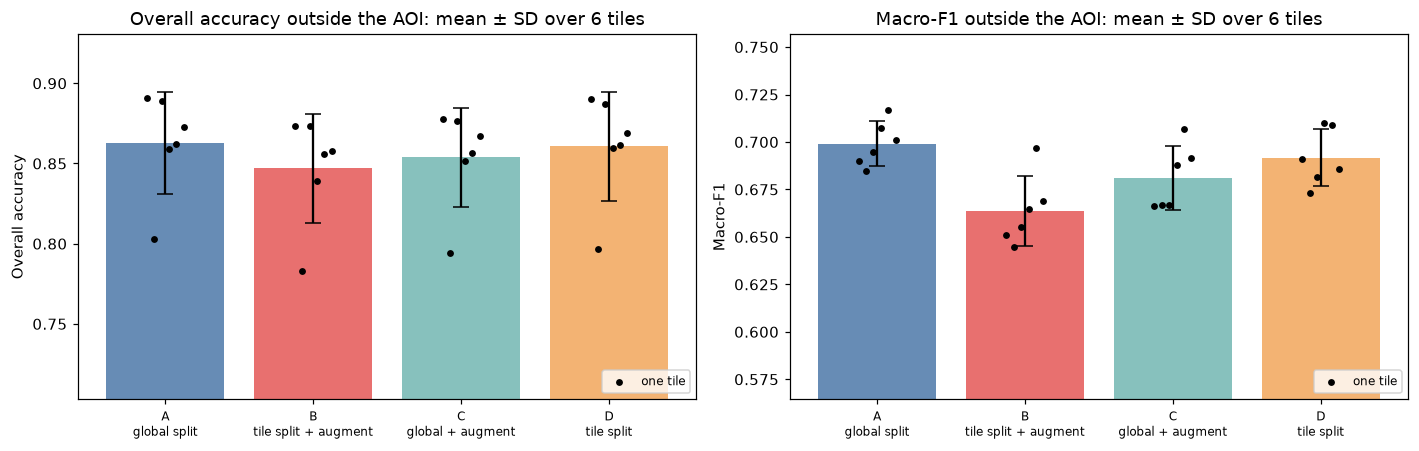

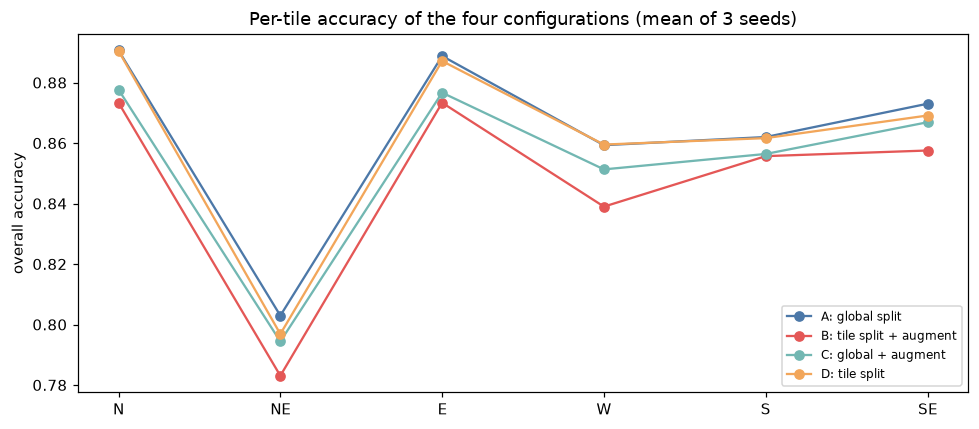

In [31]:
colors = ["#4c78a8", "#e45756", "#72b7b2", "#f2a65a"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))  # two panels
# bar positions and labels
xs = np.arange(len(CONFIGS)); labels = [c.split(": ")[0] + "\n" + c.split(": ")[1] for c in CONFIGS]
for a, (M, t_) in zip(ax, ((tile_oa, "Overall accuracy"), (tile_f1, "Macro-F1"))):  # accuracy and macro F1
    a.bar(xs, M.mean(1), yerr=M.std(1), capsize=5, color=colors, alpha=.85)  # mean over tiles with its spread
    for j, t in enumerate(TILES):  # each tile ...
        # ... as a dot
        a.scatter(xs + (j - 2.5) * 0.05, M[t], c="k", s=12, zorder=3, label="one tile" if j == 0 else None)
    a.set_xticks(xs); a.set_xticklabels(labels, fontsize=8); a.set_ylabel(t_)  # configuration labels
    # limits and legend
    a.set_ylim(max(0, M.values.min() - .08), min(1, M.values.max() + .04)); a.legend(fontsize=8, loc="lower right")
    a.set_title(f"{t_} outside the AOI: mean ± SD over 6 tiles")  # title
plt.tight_layout(); plt.show()  # arrange and draw

fig, ax = plt.subplots(figsize=(9, 4))  # one panel
for i, c in enumerate(CONFIGS):  # each configuration ...
    ax.plot(TILES, tile_oa.loc[c], "o-", c=colors[i], label=c)  # ... as a line over the tiles
# label, title and legend
ax.set_ylabel("overall accuracy"); ax.set_title("Per-tile accuracy of the four configurations (mean of 3 seeds)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()  # arrange and draw

### Is the difference between the approaches real?

The tiles are the units of replication, so the tests compare the *per-tile* scores of two approaches (paired by tile). With only six tiles the Wilcoxon test cannot give a p-value below 0.031, so the paired *t*-test and the mean difference with its SD are shown too. Pooled McNemar tests on all outside chips are added for Part 1 against Part 2; they have far more power but treat neighbouring chips as independent, so they are optimistic.


In [32]:
def paired(a, b, label):  # paired comparison of two configurations over the six tiles
    d = (tile_oa.loc[a] - tile_oa.loc[b]).values  # per-tile differences
    # paired t-test and Wilcoxon signed-rank test
    t_ = stats.ttest_rel(tile_oa.loc[a], tile_oa.loc[b]); w_ = stats.wilcoxon(tile_oa.loc[a], tile_oa.loc[b])
    # mean and spread of the difference, wins and p-values
    return {"comparison": label, "mean diff (pts)": 100 * d.mean(), "SD of diff (pts)": 100 * d.std(ddof=1),
            "tiles where first is better": f"{int((d > 0).sum())}/6", "paired t p": t_.pvalue, "Wilcoxon p": w_.pvalue}

# four comparisons
PC = pd.DataFrame([paired("A: global split", "B: tile split + augment", "A  vs  B   (Part 1 vs Part 2)"),
                   paired("A: global split", "D: tile split", "A  vs  D   (global vs tile split, no aug)"),
                   paired("D: tile split", "B: tile split + augment", "D  vs  B   (effect of augmentation, tile split)"),
                   paired("A: global split", "C: global + augment", "A  vs  C   (effect of augmentation, global split)")]).set_index("comparison")
display(PC.round(4))  # show them

# correct chips of Part 1 on all tiles
pa = np.concatenate([PRED["Part 1 (A: global split)"][t] == TD[t]["y"] for t in TILES])
# correct chips of Part 2
pb = np.concatenate([PRED["Part 2 (B: tile split + augment)"][t] == TD[t]["y"] for t in TILES])
n_a, n_b = int((pa & ~pb).sum()), int((~pa & pb).sum())  # chips only one of them got right
# McNemar exact test on those chips
print(f"pooled chips: {len(pa):,} | only A right {n_a} | only B right {n_b} | McNemar exact p = {stats.binomtest(n_a, n_a + n_b, .5).pvalue:.2g}")

,mean diff (pts),SD of diff (pts),tiles where first is better,paired t p,Wilcoxon p
comparison,,,,,
A vs B (Part 1 vs Part 2),1.5790,0.5088,6/6,0.0006,0.0312
"A vs D (global vs tile split, no aug)",0.1993,0.2502,5/6,0.1084,0.0938
"D vs B (effect of augmentation, tile split)",1.3797,0.4954,6/6,0.0010,0.0312
"A vs C (effect of augmentation, global split)",0.8893,0.3049,6/6,0.0008,0.0312


pooled chips: 57,361 | only A right 3241 | only B right 2259 | McNemar exact p = 3.8e-40


In [33]:
# per-class F1 of each approach on every tile
f1 = {k: pd.DataFrame({t: REP[k][t]["per_class"]["f1"] for t in TILES}) for k in APPROACH}
# mean and spread over the tiles
PCF = pd.DataFrame({f"{k.split(' (')[0]} mean": f1[k].mean(1) for k in APPROACH} | {f"{k.split(' (')[0]} SD": f1[k].std(1) for k in APPROACH})
PCF = PCF[["Part 1 mean", "Part 1 SD", "Part 2 mean", "Part 2 SD"]]  # column order
# reference chips per class
PCF["support (all tiles)"] = sum(REP[list(APPROACH)[0]][t]["per_class"]["support"] for t in TILES)
print("F1 per class: mean and SD across the six tiles")  # header
PCF.round(3)  # show it

F1 per class: mean and SD across the six tiles


,Part 1 mean,Part 1 SD,Part 2 mean,Part 2 SD,support (all tiles)
Corn,0.928,0.021,0.918,0.021,28063
Soybeans,0.920,0.016,0.911,0.016,17917
Grass/pasture,0.577,0.061,0.562,0.062,4602
Developed,0.604,0.060,0.558,0.065,3228
Other,0.405,0.114,0.473,0.111,3551


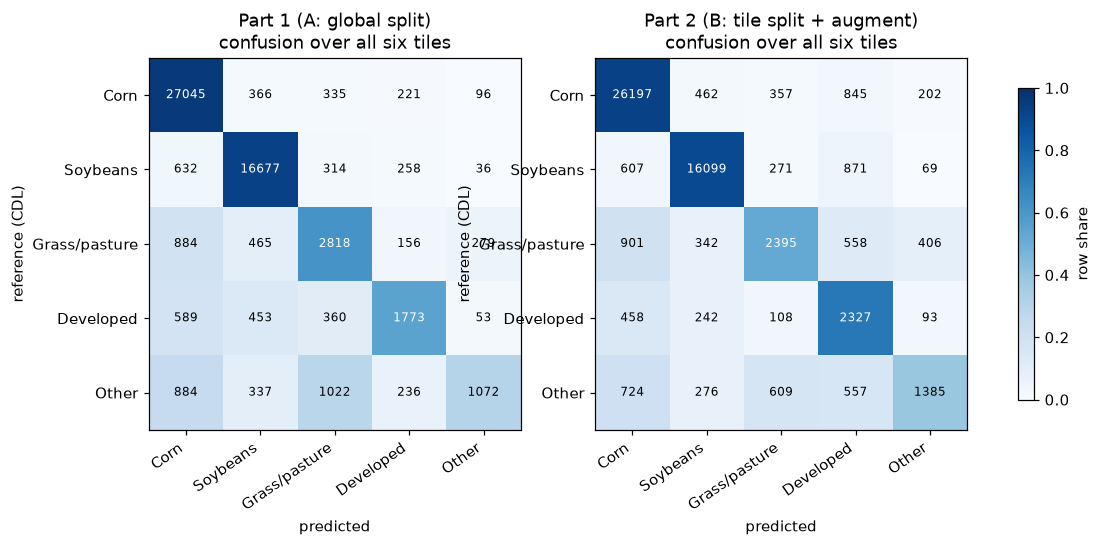

In [34]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))  # two panels
for a, k in zip(ax, APPROACH):  # each approach
    # confusion summed over the tiles, and row shares
    cmx = sum(REP[k][t]["confusion_matrix"].values for t in TILES); frac = cmx / cmx.sum(1, keepdims=True).clip(1)
    im = a.imshow(frac, cmap="Blues", vmin=0, vmax=1)  # shares as colours
    # class names on both axes
    a.set_xticks(range(5)); a.set_xticklabels(NAMES, rotation=35, ha="right"); a.set_yticks(range(5)); a.set_yticklabels(NAMES)
    for i in range(5):  # every cell ...
        for j in range(5):  # ...
            # its count
            a.text(j, i, int(cmx[i, j]), ha="center", va="center", color="white" if frac[i, j] > .5 else "black", fontsize=8)
    # title and axis labels
    a.set_title(f"{k}\nconfusion over all six tiles"); a.set_xlabel("predicted"); a.set_ylabel("reference (CDL)")
plt.colorbar(im, ax=ax, label="row share", shrink=.8); plt.show()  # colour bar, draw

### Maps of all six tiles: CDL and both predictions

`predict_chip_map` is run over every tile with both models (stride 8, no retraining). Three figures follow, each laid out 2 × 3 in the same geographic order (top: N, NE, E; bottom: W, S, SE): the **CDL reference**, the **Part 1** prediction and the **Part 2** prediction. The titles give the pixel-level agreement with CDL.


pixel-level agreement with CDL (share of valid pixels)


,Part 1,Part 2
N,0.790,0.779
NE,0.705,0.688
E,0.790,0.779
W,0.752,0.754
S,0.764,0.771
SE,0.779,0.769
mean,0.763,0.756
SD,0.032,0.035


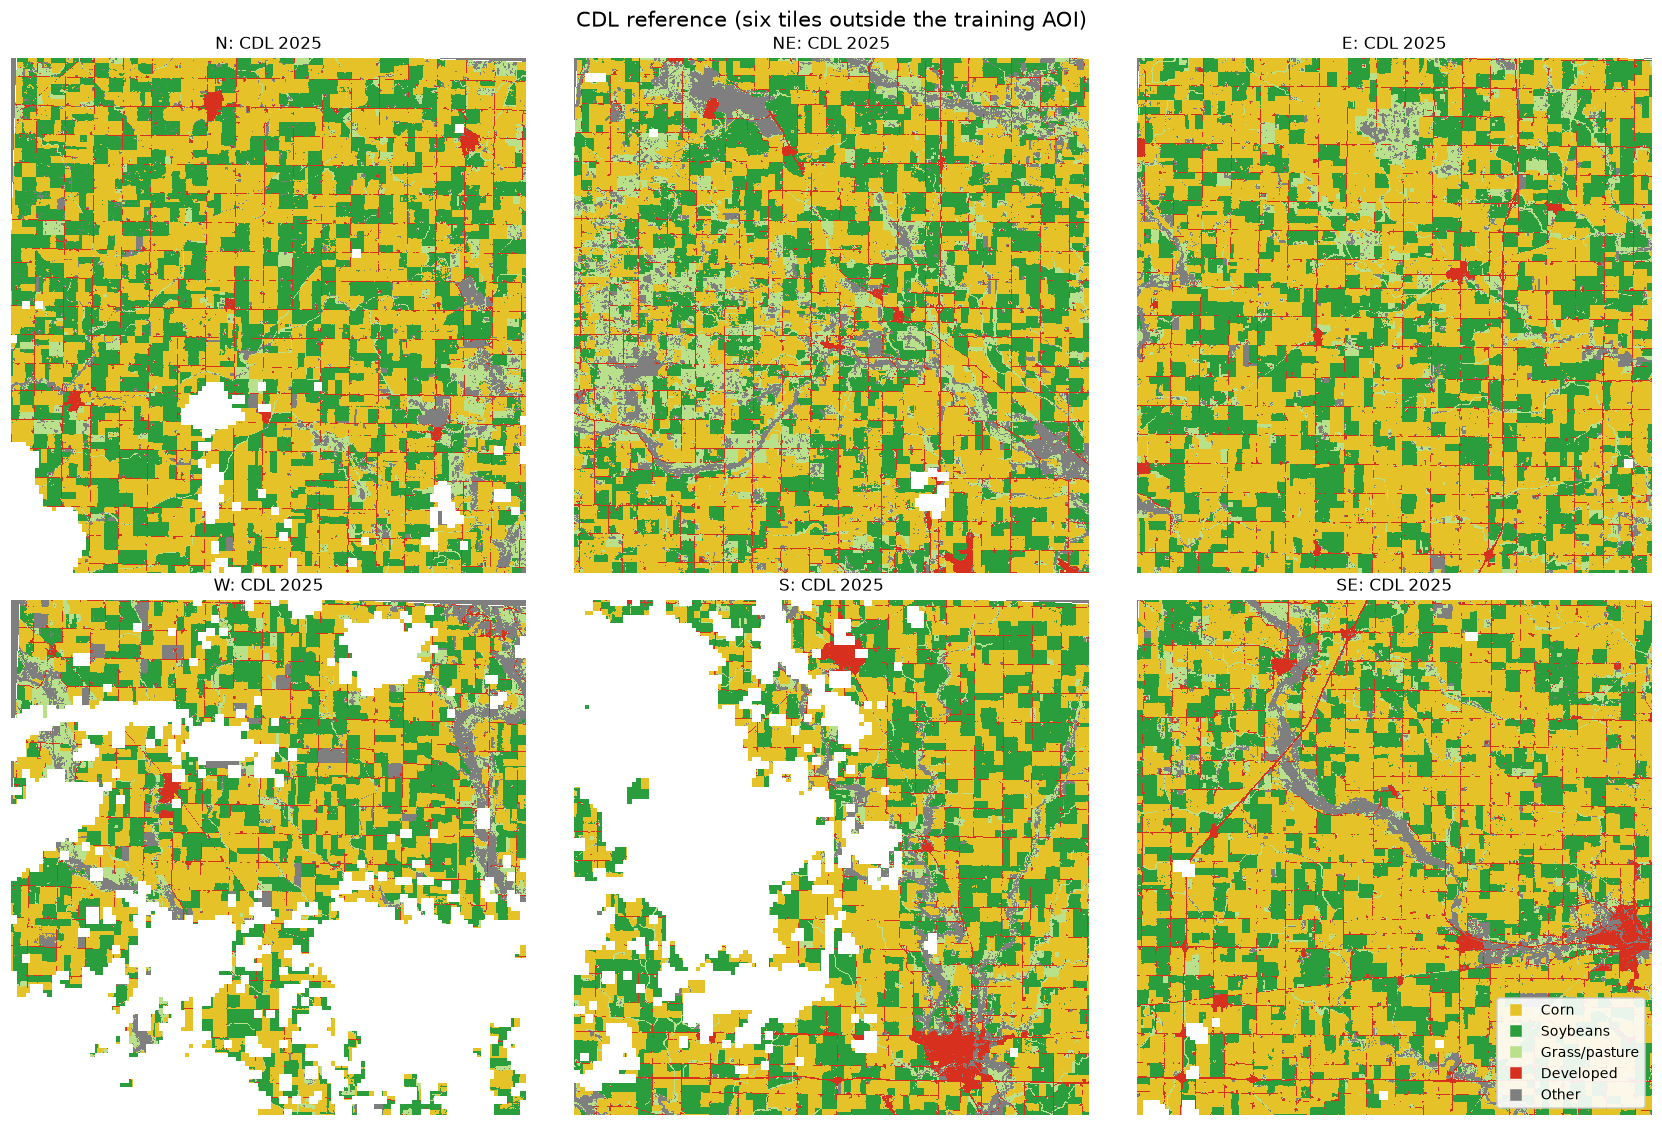

In [35]:
def chip_map_t(res, t, stride=8):  # class map of a tile from a sliding chip window
    # predicted class of each chip, painted on its pixels
    return ic.predict_chip_map(res["model"], TD[t]["refl"], size=SIZE, stride=stride, normalizer=res["norm"], device=DEVICE).values

# maps of both approaches on every tile
PM = {k: {t: chip_map_t(r, t) for t in TILES} for k, r in APPROACH.items()}
# pixels with both predictions and a label
VALID = {t: (PM["Part 1 (A: global split)"][t] >= 0) & (PM["Part 2 (B: tile split + augment)"][t] >= 0) & (TD[t]["lab"] >= 0) for t in TILES}
# pixel agreement with the CDL
PIX = pd.DataFrame({k.split(" (")[0]: {t: np.mean((PM[k][t] == TD[t]["lab"])[VALID[t]]) for t in TILES} for k in APPROACH})
PIX.loc["mean"] = PIX.mean(); PIX.loc["SD"] = PIX.iloc[:-1].std()  # mean and spread over the tiles
print("pixel-level agreement with CDL (share of valid pixels)")  # header
display(PIX.round(3))  # show it

def grid_figure(getter, title, legend=True):  # a 2 x 3 grid of tile maps
    fig, axs = plt.subplots(2, 3, figsize=(15.5, 10.4))  # the panels
    for i, row in enumerate(TILE_GRID):  # each row ...
        for j, t in enumerate(row):  # ... and tile
            img, ttl = getter(t)  # image and title from the getter
            # draw it
            axs[i, j].imshow(img, cmap=cm, vmin=0, vmax=4, interpolation="nearest"); axs[i, j].set_title(ttl, fontsize=11); axs[i, j].axis("off")
    if legend:  # legend wanted
        # one entry per class
        for n_, c_ in zip(NAMES, range(5)): axs[1, 2].plot([], [], "s", c=cm(c_), label=n_)
        axs[1, 2].legend(loc="lower right", fontsize=9, framealpha=.9)  # the legend
    fig.suptitle(title, fontsize=14); plt.tight_layout(); plt.show()  # title, arrange and draw

# the CDL of every tile
grid_figure(lambda t: (np.ma.masked_where(~VALID[t], TD[t]["lab"]), f"{t}: CDL 2025"), "CDL reference (six tiles outside the training AOI)")

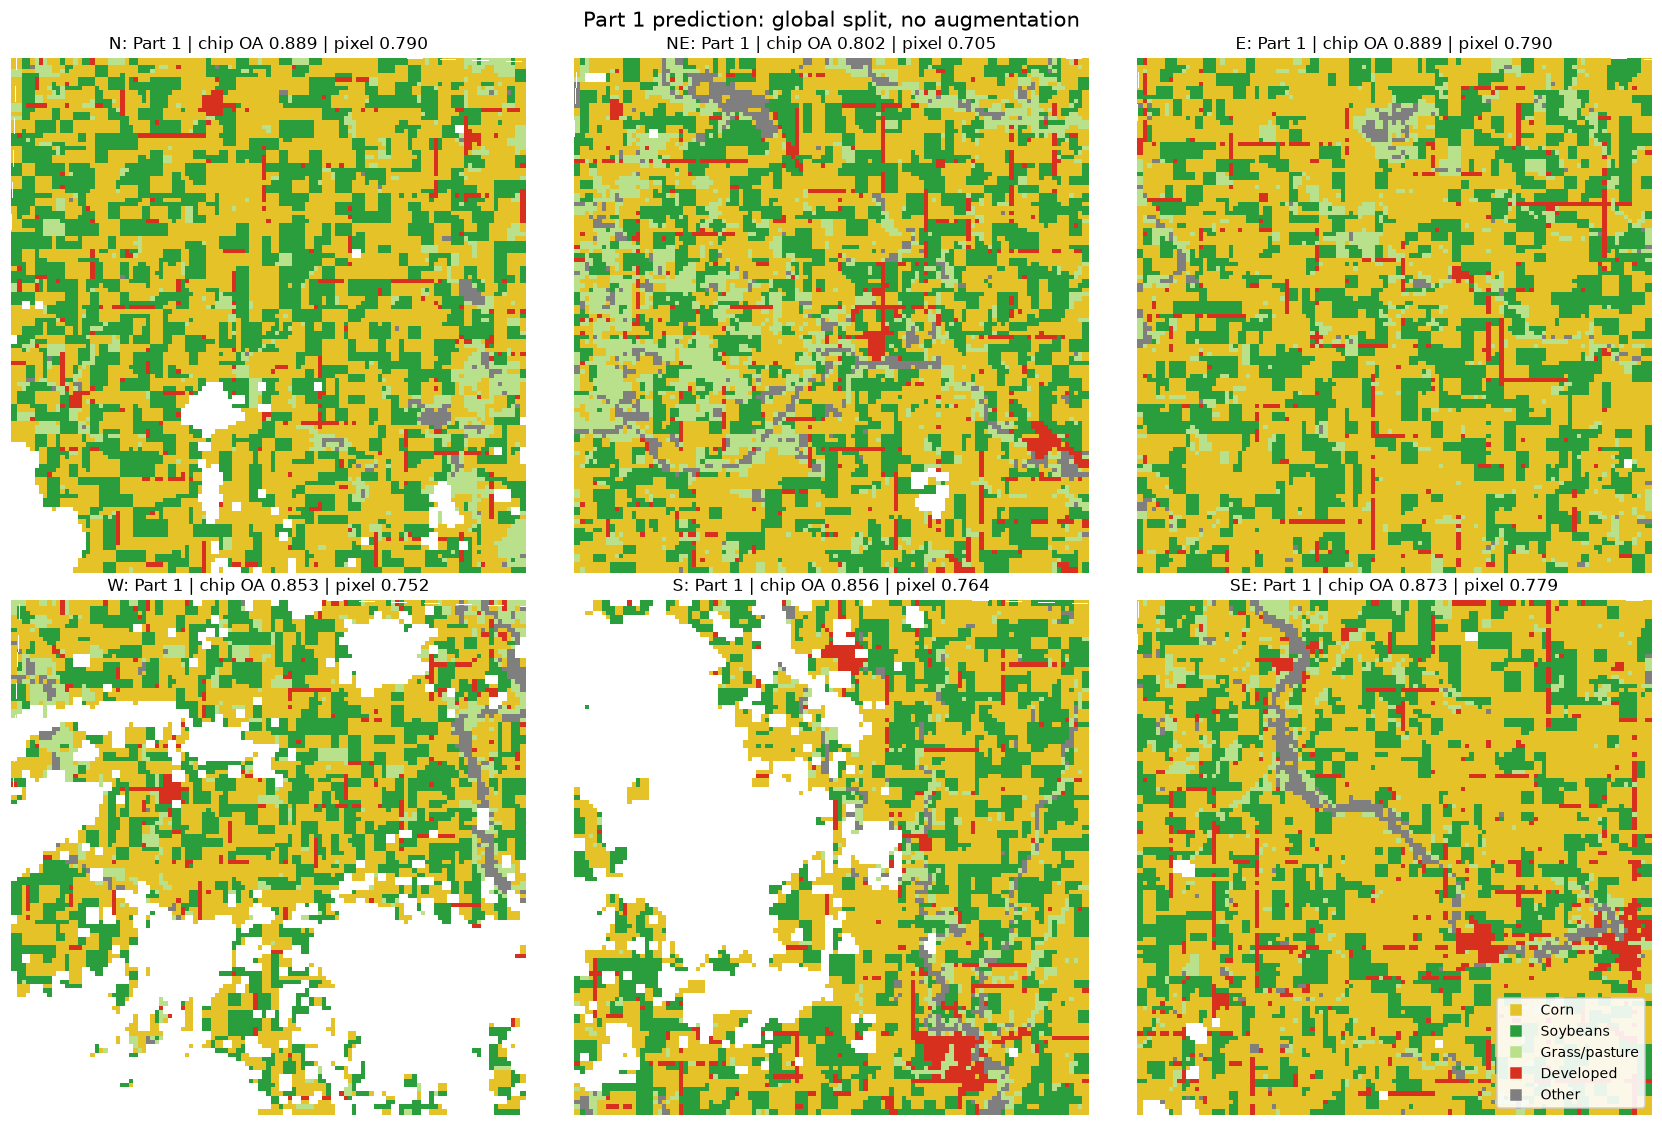

In [36]:
k1 = "Part 1 (A: global split)"  # the Part 1 key
# Part 1 predictions with their chip and pixel accuracy
grid_figure(lambda t: (np.ma.masked_where(~VALID[t], PM[k1][t]),
                       f"{t}: Part 1 | chip OA {REP[k1][t]['overall_accuracy']:.3f} | pixel {PIX.loc[t, 'Part 1']:.3f}"),
            "Part 1 prediction: global split, no augmentation")

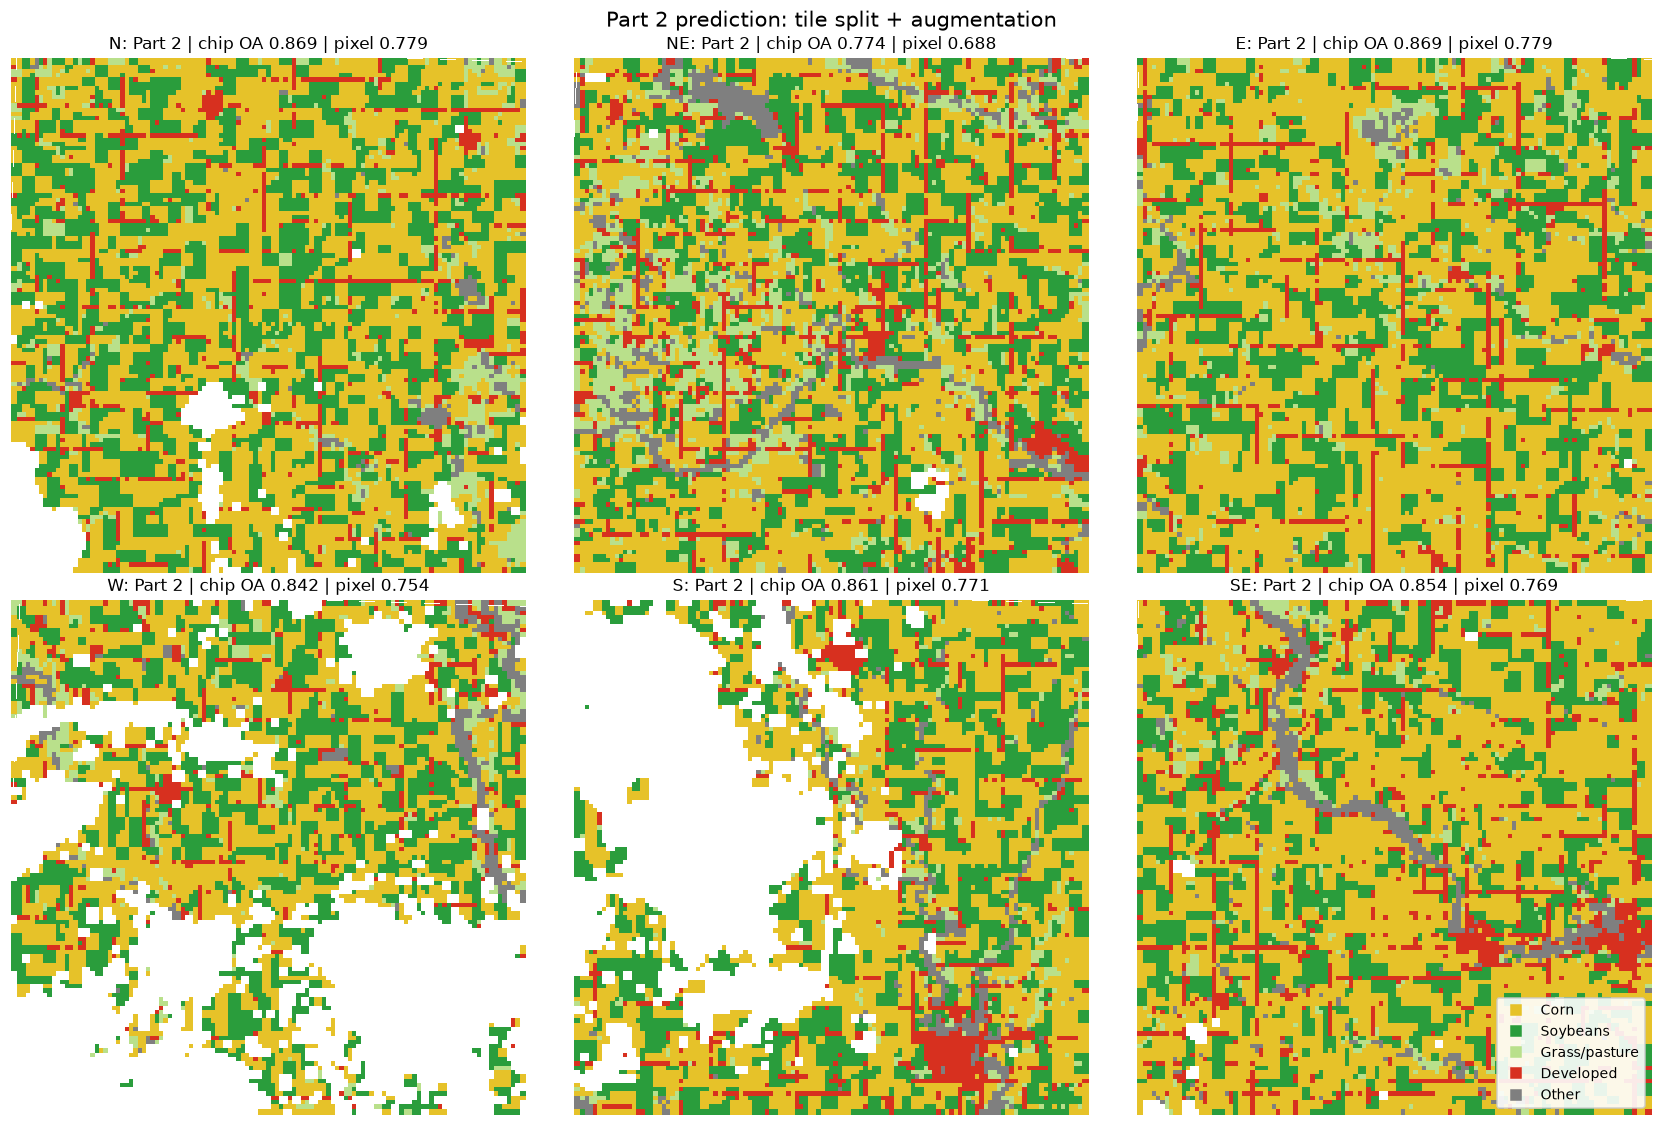

In [37]:
k2 = "Part 2 (B: tile split + augment)"  # the Part 2 key
# Part 2 predictions with their chip and pixel accuracy
grid_figure(lambda t: (np.ma.masked_where(~VALID[t], PM[k2][t]),
                       f"{t}: Part 2 | chip OA {REP[k2][t]['overall_accuracy']:.3f} | pixel {PIX.loc[t, 'Part 2']:.3f}"),
            "Part 2 prediction: tile split + augmentation")

Where do the two approaches disagree with the reference? Green is a pixel both models classify correctly, blue only Part 1, orange only Part 2, red neither.


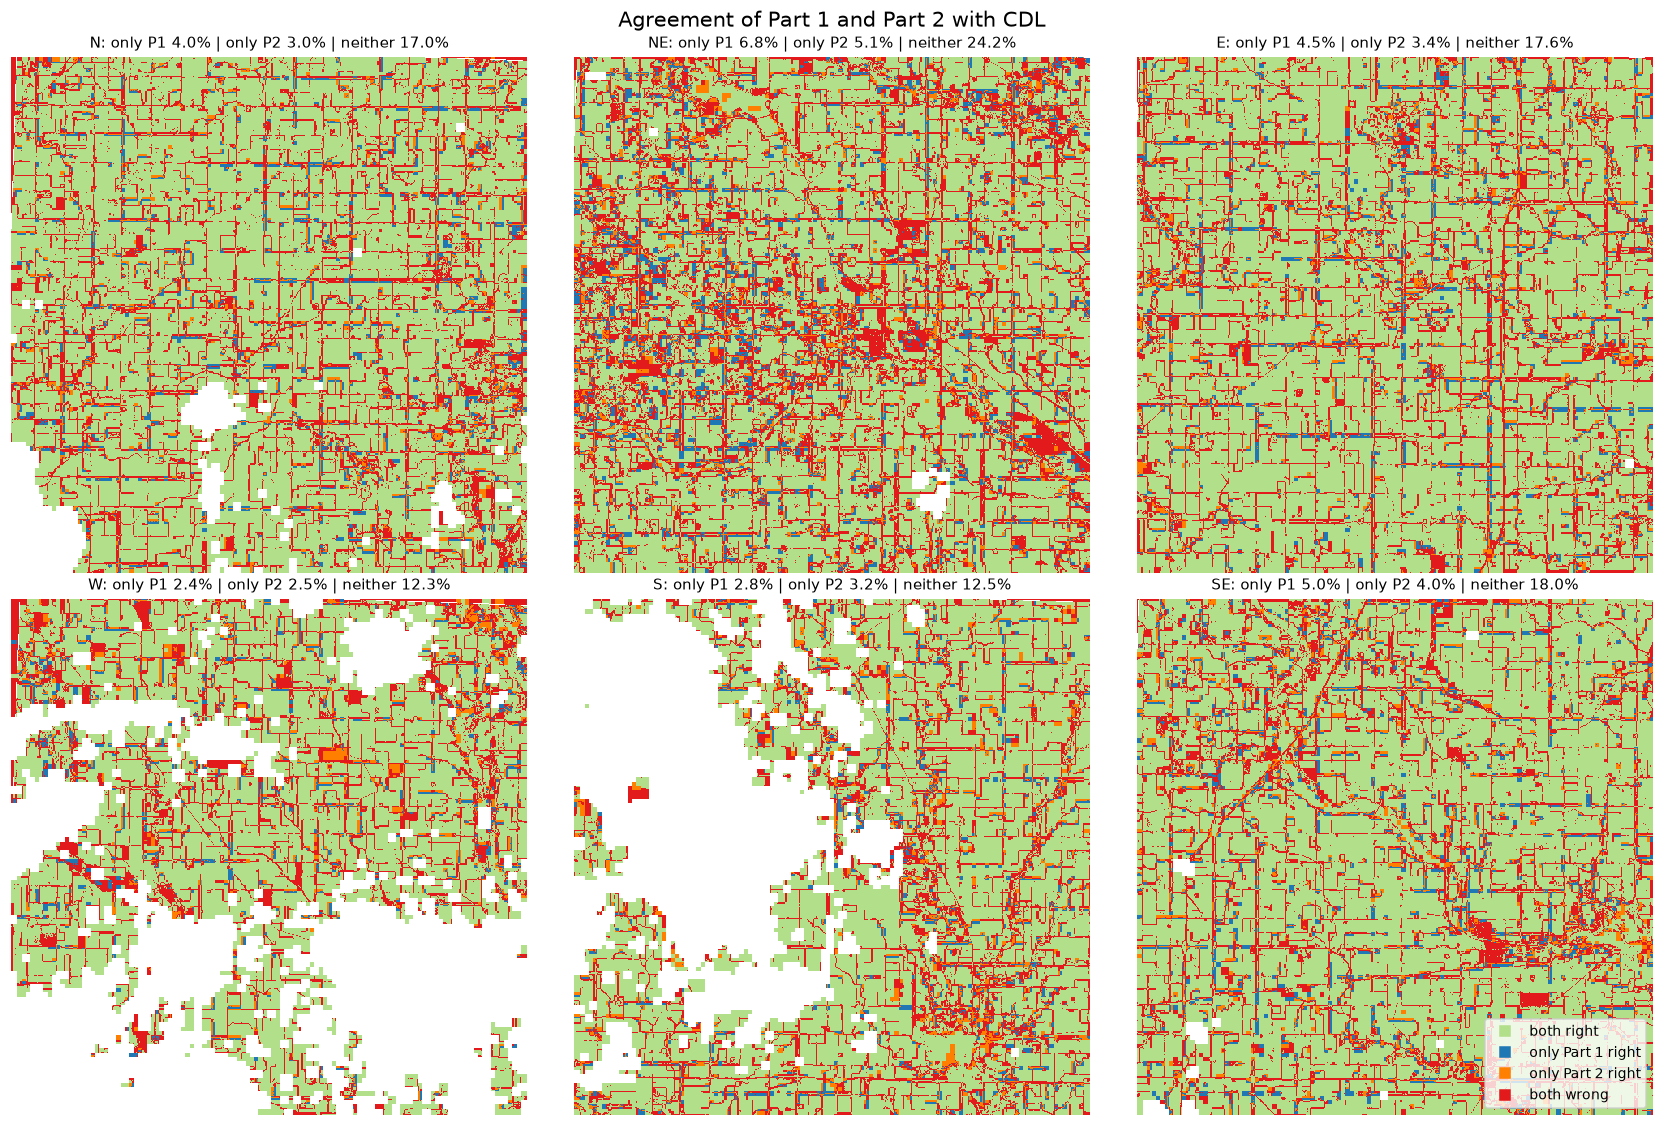

In [38]:
cc_ = plt.matplotlib.colors.ListedColormap(["#b2df8a", "#1f78b4", "#ff7f00", "#e31a1c"])
fig, axs = plt.subplots(2, 3, figsize=(15.5, 10.4))  # the panels
shares = {}  # share of each agreement category per tile
for i, row in enumerate(TILE_GRID):  # each row ...
    for j, t in enumerate(row):  # ... and tile
        a_ok, b_ok = PM[k1][t] == TD[t]["lab"], PM[k2][t] == TD[t]["lab"]  # correct pixels of Part 1 and Part 2
        cat = np.full(TD[t]["lab"].shape, np.nan)  # category map
        # both right, only Part 1, only Part 2, both wrong
        cat[VALID[t] & a_ok & b_ok] = 0; cat[VALID[t] & a_ok & ~b_ok] = 1; cat[VALID[t] & ~a_ok & b_ok] = 2; cat[VALID[t] & ~a_ok & ~b_ok] = 3
        shares[t] = [np.nanmean(cat == q) for q in range(4)]  # share of each category
        # draw the categories
        axs[i, j].imshow(np.ma.masked_invalid(cat), cmap=cc_, vmin=0, vmax=3, interpolation="nearest"); axs[i, j].axis("off")
        # title with the shares
        axs[i, j].set_title(f"{t}: only P1 {shares[t][1]*100:.1f}% | only P2 {shares[t][2]*100:.1f}% | neither {shares[t][3]*100:.1f}%", fontsize=10)
# legend entries
for q, l in enumerate(["both right", "only Part 1 right", "only Part 2 right", "both wrong"]): axs[1, 2].plot([], [], "s", c=cc_(q), label=l)
# legend, title, arrange and draw
axs[1, 2].legend(loc="lower right", fontsize=9); fig.suptitle("Agreement of Part 1 and Part 2 with CDL", fontsize=14); plt.tight_layout(); plt.show()

### Reading the six-tile results

* **Accuracy outside the AOI is lower and varies by tile.** Part 1 averages OA **0.861 ± 0.034** (mean ± SD over six tiles) and Part 2 **0.851 ± 0.032**, against 0.910 and 0.902 on the in-AOI test blocks, a drop of about 5 points. The spread between tiles (0.80 to 0.89) is much larger than the spread between training seeds (SD 0.002 to 0.005), so **where** the model is applied matters more than **how often** it is retrained. NE is the hardest tile (OA 0.80 / 0.79): it has about twice as much grass/pasture and "Other" as the training AOI, classes the models only learned from a few hundred chips.
* **Part 1 is better than Part 2 on every tile.** The mean difference is **1.3 points of OA (SD 0.2)**, with Part 1 ahead on 6 of 6 tiles (paired t-test p < 0.001, Wilcoxon p = 0.031, the smallest value possible with six tiles; pooled McNemar p ≈ 1e-17, which is optimistic because neighbouring chips are not independent). The gap is small compared with the tile-to-tile SD, so the choice does not change what you can say about any single map, but it is consistent.
* **The ablation agrees.** Across all 12 models the order is A (0.863) > C (0.855) ≈ D (0.855) > B (0.850). Augmentation costs about 0.9 points on the global split (6 of 6 tiles) and about 0.5 points on the tile split (5 of 6 tiles, Wilcoxon p = 0.09, so weaker evidence). Here the tile split without augmentation (D) was equal to A in-AOI but about 0.9 points worse outside, so the in-AOI test could not separate them while the outside tiles could.
* **Class-wise.** Corn and soybeans are stable (F1 0.91 to 0.93, SD below 0.02). The minority classes drive the differences: Part 1 is better for Grass/pasture (0.59 vs 0.52) and Developed (0.63 vs 0.57), while Part 2 is better for "Other" (0.50 vs 0.38). All three have an SD of 0.06 to 0.11 across tiles, so their ranking is the least certain part of the comparison.
* **Maps tell a slightly different story.** Judged pixel by pixel, Part 2 agrees marginally *more* with CDL (mean 0.767 vs 0.758, better on 5 of 6 tiles). The chip-level score looks at the central pixel of overlapping windows, while the maps use the full stride-8 mosaic, which is dominated by field edges and by the thin roads and farmsteads that both models draw as Developed (thin red lines). The difference (about 1 point) is within the tile SD (0.03), so the maps do not overturn the chip-level ranking but they do show that the margin depends on how the result is measured.
* **Conclusion.** With six tiles, the plain global block split gives the most accurate and most consistent classifier, by a small margin (about 1 point of OA); offline augmentation did not help here, and a per-tile split mainly improves how representative the evaluation is rather than the accuracy. Realistic expected accuracy for this scene is about **0.86 ± 0.03 OA** and about 0.70 macro-F1, not the 0.91 of the in-AOI test.
* **Caveats.** All tiles lie within about 40 km of the AOI and come from one scene and one year; W and S contain 19 % cloud-masked area (white in the maps), which is excluded; CDL labels are themselves a classification; six tiles give limited power, so differences below about one SD (0.03) are reported as consistent, not as large.


### Summary

| Step | What was done |
|---|---|
| Data | Landsat surface reflectance (6 bands, QA-masked) and CDL 2025 reprojected to the Landsat grid, 5 classes |
| Chips | 16 × 16 px, stride 8, wholly inside 64-px blocks so no pixel is shared across splits |
| Model | `simple_cnn`, AdamW, cosine schedule, class-weighted cross-entropy, early stopping on validation accuracy, GPU |
| Part 1 | One global 60/20/20 block split |
| Part 2 | 9 tiles, per-tile 60/20/20 split, 3 augmented copies of each training chip, merge |
| Part 3 | Own and common test sets, three seeds, 2 × 2 ablation, bootstrap CIs |
| Part 4 | Both approaches (and the 12-model ablation) applied without retraining to six non-overlapping tiles outside the AOI (N, NE, E, W, S, SE; same scene date, CDL 2025): OA mean ± SD over tiles 0.861 ± 0.034 (Part 1) vs 0.851 ± 0.032 (Part 2), paired tests across tiles, per-class F1 with SD, 2 × 3 maps of CDL and both predictions |
